# Exploratory Data Analysis and Visualization of Bank Telemarketing Campaigns
**Course:** U21ADP05 Exploratory Data Analysis and Visualization - KPR Institute of Engineering and Technology (Assignment II)  
**Dataset:** UCI *Bank Marketing* (Moro, Cortez & Rita, 2014) - 45,211 calls, 16 input features + target `y` (term-deposit subscription)

This notebook follows the **seven stages of visualization** (Fry, 2007): Acquire -> Parse -> Filter -> Mine -> Represent -> Refine -> Interact, then builds and evaluates a deep-learning model (MLP).
All reusable code lives in `src/`; the notebook calls it and shows the results. Run it from the repository root or from `notebooks/`.

| Stage | Where |
|---|---|
| 1 Acquire | Section 1 |
| 2 Parse | Section 2 |
| 3 Filter | Section 3 |
| 4 Mine | Section 4 |
| 5 Represent, 6 Refine | Section 5 |
| 7 Interact | Section 6 |
| Deep learning + evaluation | Sections 7-8 |

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

from src.config import FIG_DIR, RES_DIR, RAW_CSV
from src.data_loader import get_data, sha256
from src.preprocessing import clean, split_data, prepare_matrices
from src.eda import run_eda, structure_report, quality_report, before_after_skew
from src.visualizations import make_all_eda_figures


## 1. Acquire
Download (UCI first, verified mirror as fallback), validate shape/columns and record a checksum.

In [2]:
raw = get_data()
print("shape:", raw.shape, "| SHA-256:", sha256(RAW_CSV))
raw.head()

shape: (45211, 17) | SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Parse
Structure, data types and data quality. The file has no NaN cells, but missing information is hidden in `'unknown'` labels and the sentinel `pdays = -1`.

In [3]:
display(structure_report(raw))
display(quality_report(raw))
display(raw.sample(5, random_state=42))

,dtype,n_unique,n_missing_NaN,pct_missing_NaN,memory_KB
age,int64,77,0,0.0,353.2
job,str,12,0,0.0,2582.2
marital,str,3,0,0.0,2465.1
education,str,4,0,0.0,2530.8
default,str,2,0,0.0,2252.5
balance,int64,7168,0,0.0,353.2
housing,str,2,0,0.0,2276.3
loan,str,2,0,0.0,2258.8
contact,str,3,0,0.0,2506.8
day,int64,31,0,0.0,353.2


,column,issue,count,pct
0,job,'unknown' label,288,0.640
1,marital,'unknown' label,0,0.000
2,education,'unknown' label,1857,4.110
3,default,'unknown' label,0,0.000
4,housing,'unknown' label,0,0.000
5,loan,'unknown' label,0,0.000
6,contact,'unknown' label,13020,28.800
7,month,'unknown' label,0,0.000
8,poutcome,'unknown' label,36959,81.750
9,pdays,sentinel -1 (never contacted),36954,81.740


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,unknown,16,may,192,1,-1,0,unknown,no
9928,47,services,single,secondary,no,3644,no,no,unknown,9,jun,83,2,-1,0,unknown,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,unknown,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,unknown,no


## 3. Filter
Cleaning, feature construction, leakage-safe preprocessing and train/validation/test splitting. Learned transformations (caps, scalers, one-hot categories) are **fitted on the training split only**.

In [4]:
cdf = clean(raw)
train, val, test = split_data(cdf, "stratified")
print({k: (len(v), round(v.y_bin.mean(), 4)) for k, v in dict(train=train, val=val, test=test).items()})
Xtr, Xva, Xte, ytr, yva, yte, pre, names = prepare_matrices(train, val, test)
print("model inputs:", len(names), "| train matrix:", Xtr.shape)
display(before_after_skew(train, Xtr, names).round(2))

{'train': (31647, np.float64(0.117)), 'val': (6782, np.float64(0.1169)), 'test': (6782, np.float64(0.1169))}
model inputs: 51 | train matrix: (31647, 51)


,variable,skew_before,skew_after,kurtosis_before,kurtosis_after
0,balance,8.32,-1.58,133.40,1.79
1,campaign,4.91,1.18,38.89,1.14
2,previous,7.67,2.34,103.50,4.56
3,pdays_clean,2.61,1.72,6.83,1.02


## 4. Mine
All statistics (univariate, distribution fitting, bivariate tests, logistic regression) are computed in `src/eda.py`.

In [5]:
R = run_eda(raw, cdf, train, save=False); T = R["_tables"]
display(T["numeric_summary"].round(2))
display(T["outliers_iqr"].round(2))

,count,missing,mean,median,mode,min,max,range,variance,std,Q1,Q3,IQR,skewness,excess_kurtosis
age,45211.0,0.0,40.94,39.0,32.0,18.0,95.0,77.0,112.76,10.62,33.0,48.0,15.0,0.68,0.32
balance,45211.0,0.0,1362.27,448.0,0.0,-8019.0,102127.0,110146.0,9270598.95,3044.77,72.0,1428.0,1356.0,8.36,140.74
day,45211.0,0.0,15.81,16.0,20.0,1.0,31.0,30.0,69.26,8.32,8.0,21.0,13.0,0.09,-1.06
duration,45211.0,0.0,258.16,180.0,124.0,0.0,4918.0,4918.0,66320.57,257.53,103.0,319.0,216.0,3.14,18.15
campaign,45211.0,0.0,2.76,2.0,1.0,1.0,63.0,62.0,9.60,3.10,1.0,3.0,2.0,4.90,39.25
pdays,45211.0,0.0,40.20,-1.0,-1.0,-1.0,871.0,872.0,10025.77,100.13,-1.0,-1.0,0.0,2.62,6.93
previous,45211.0,0.0,0.58,0.0,0.0,0.0,275.0,275.0,5.31,2.30,0.0,0.0,0.0,41.85,4506.36


,variable,lower_fence,upper_fence,n_below,n_above,pct_outliers,n_extreme(>3IQR),max,p99
0,age,10.5,70.5,0,487,1.08,3,95,71.0
1,balance,-1962.0,3462.0,17,4712,10.46,2443,102127,13164.9
2,duration,-221.0,643.0,0,3235,7.16,1155,4918,1269.0
3,campaign,-2.0,6.0,0,3064,6.78,1462,63,16.0
4,previous,0.0,0.0,0,8257,18.26,8257,275,8.9


In [6]:
print("Bernoulli outcome:", {k: round(v, 4) for k, v in R["bernoulli"].items()})
display(pd.DataFrame([R["campaign_counts"], R["previous_counts"]]).set_index("variable").T.round(3))
display(T["fit_age"]); display(T["fit_duration"])

Bernoulli outcome: {'k': 5289, 'n': 45211, 'p_hat': 0.117, 'ci_low': 0.114, 'ci_high': 0.12, 'variance_p_1_minus_p': 0.1033, 'month_homogeneity_chi2': np.float64(3061.8389), 'month_homogeneity_dof': 11, 'month_homogeneity_p': np.float64(0.0), 'monthly_rate_min': 0.0672, 'monthly_rate_max': 0.5199}


variable,campaign-1 (extra contacts),previous
n,45211.000,4.521100e+04
mean,1.764,5.800000e-01
variance,9.598,5.306000e+00
dispersion_index_var_over_mean,5.441,9.143000e+00
poisson_lambda,1.764,5.800000e-01
poisson_loglik,-110183.014,-6.647501e+04
poisson_AIC,220368.028,1.329520e+05
poisson_chi2,524771.401,3.739760e+08
poisson_dof,8.000,8.000000e+00
poisson_p,0.000,0.000000e+00


,distribution,params,loglik,AIC,KS_D,KS_p,delta_AIC
0,lognormal,"(0.2546, 0.0, 39.6239)",-168646.495882,337296.991764,0.060978,1.393075e-146,0.000000
1,gamma,"(15.5109, 0.0, 2.6392)",-169014.177867,338032.355734,0.072933,1.401546e-209,735.363970
2,normal,"(40.9362, 10.6186)",-170967.653171,341939.306342,0.095982,0.000000e+00,4642.314578


,distribution,params,loglik,AIC,KS_D,KS_p,delta_AIC
0,lognormal,"(0.9328, 0.0, 174.6112)",-294392.742683,588789.485365,0.037982,4.208158e-57,0.000000
1,gamma,"(1.4221, 0.0, 181.5481)",-294726.682460,589457.364920,0.056712,7.984348e-127,667.879555
2,weibull,"(1.1594, 0.0, 273.429)",-295417.071983,590838.143967,0.060670,4.261159e-145,2048.658602
3,exponential,"(0.0, 258.1802)",-296277.763411,592557.526823,0.106047,0.000000e+00,3768.041457


In [7]:
display(T["mannwhitney"].round(3)); display(T["chi2_target"].round(3))
display(T["logit_odds_ratios"].assign(effect=lambda d: np.abs(np.log(d.odds_ratio))).sort_values("effect", ascending=False).head(12).drop(columns="effect").round(3))
print("VIF max before/after removing redundant history variables:", round(R["vif"]["max_before"]), "->", round(R["vif"]["max_after"], 1))

,variable,median_yes,median_no,mean_yes,mean_no,U,p_value,cliffs_delta
0,duration,426.0,164.0,537.295,221.183,170521757.0,0.000,0.615
1,previous,0.0,0.0,1.170,0.502,127174833.0,0.000,0.205
2,pdays_clean,0.0,0.0,69.343,37.262,125257746.5,0.000,0.186
3,balance,733.0,417.0,1804.268,1303.715,124589983.5,0.000,0.180
4,campaign,2.0,2.0,2.141,2.846,90300543.5,0.000,-0.145
5,day,15.0,16.0,15.158,15.892,99974112.0,0.000,-0.053
6,age,38.0,39.0,41.670,40.839,103915109.5,0.063,-0.016


,variable,chi2,dof,p_value,cramers_v
0,poutcome,4391.507,3,0.0,0.312
1,month,3061.839,11,0.0,0.260
2,contact,1035.714,2,0.0,0.151
3,housing,874.822,1,0.0,0.139
4,job,836.105,11,0.0,0.135
5,education,238.924,3,0.0,0.072
6,loan,209.617,1,0.0,0.068
7,marital,196.496,2,0.0,0.066
8,default,22.202,1,0.0,0.022


,odds_ratio,ci_low,ci_high,p_value
poutcome_success,7.243,5.803,9.041,0.0
month_mar,4.208,3.283,5.394,0.0
contact_unknown,0.278,0.239,0.322,0.0
month_sep,3.169,2.488,4.036,0.0
month_dec,2.870,1.988,4.143,0.0
month_oct,2.725,2.183,3.400,0.0
month_jan,0.526,0.411,0.675,0.0
housing_no,1.720,1.571,1.883,0.0
month_jun,1.717,1.461,2.019,0.0
job_retired,1.668,1.371,2.029,0.0


VIF max before/after removing redundant history variables: 1005 -> 5.2


## 5. Represent and 6. Refine - exploratory figures
Each figure is followed by its question, what it shows, why the chart was chosen, the variables, the finding, interpretation and caveats.

In [8]:
figs = make_all_eda_figures(cdf, R)
print(len(figs), "figures saved to", FIG_DIR)

14 figures saved to /home/claude/bank-marketing-eda-dl/outputs/figures


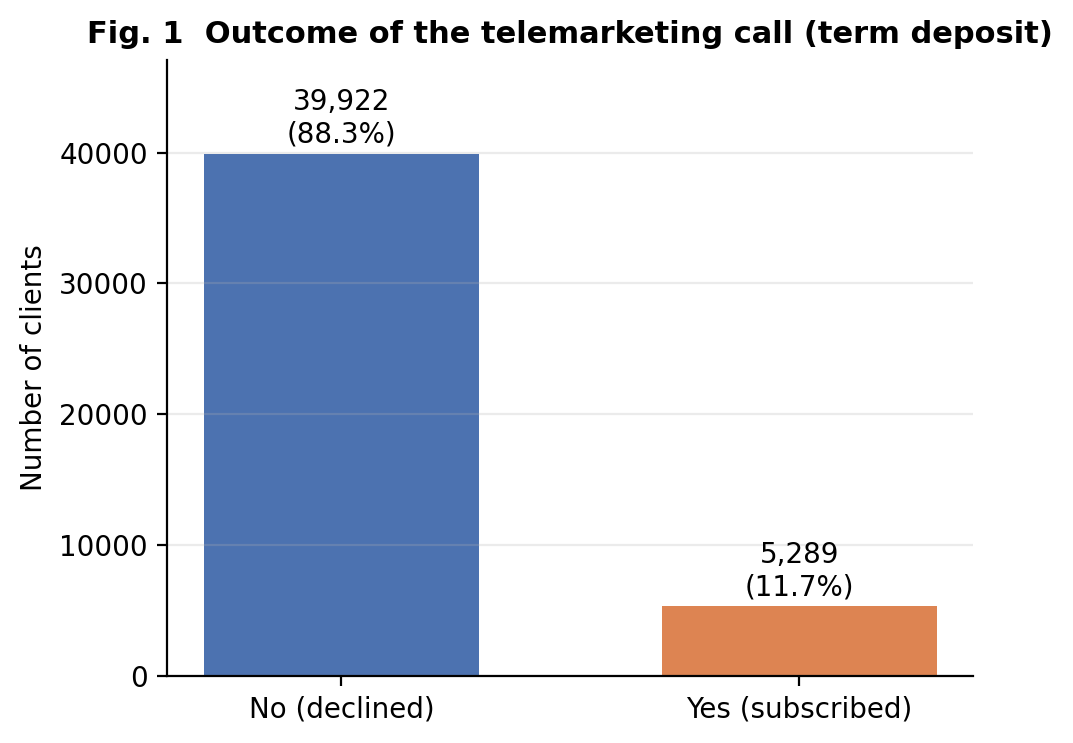

In [9]:
display(Image(str(FIG_DIR / 'fig01_class_balance.png'), width=900))

**Figure 1 - Class balance of the target variable**

| | |
|---|---|
| **Question** | How imbalanced is the outcome (did the client subscribe to a term deposit)? |
| **What it shows** | Number and share of clients in each outcome class. |
| **Why this chart** | A bar chart is the simplest faithful encoding of a binary categorical variable and the class ratio decides which evaluation metrics are meaningful. |
| **Variables** | y (categorical, binary). |
| **Finding** | 5,289 of 45,211 clients subscribed (p-hat = 11.70%, exact 95% CI 11.40%-12.00%); the classes are about 7.5:1. |
| **Interpretation** | The outcome is well modelled as a Bernoulli(p = 0.117) variable. A classifier that always answers 'no' would already be 88.3% accurate, so accuracy is uninformative and ROC-AUC, PR-AUC and F1 are used instead. |
| **Caveats** | The rate describes this particular campaign and its client selection, not the general population of bank customers. |

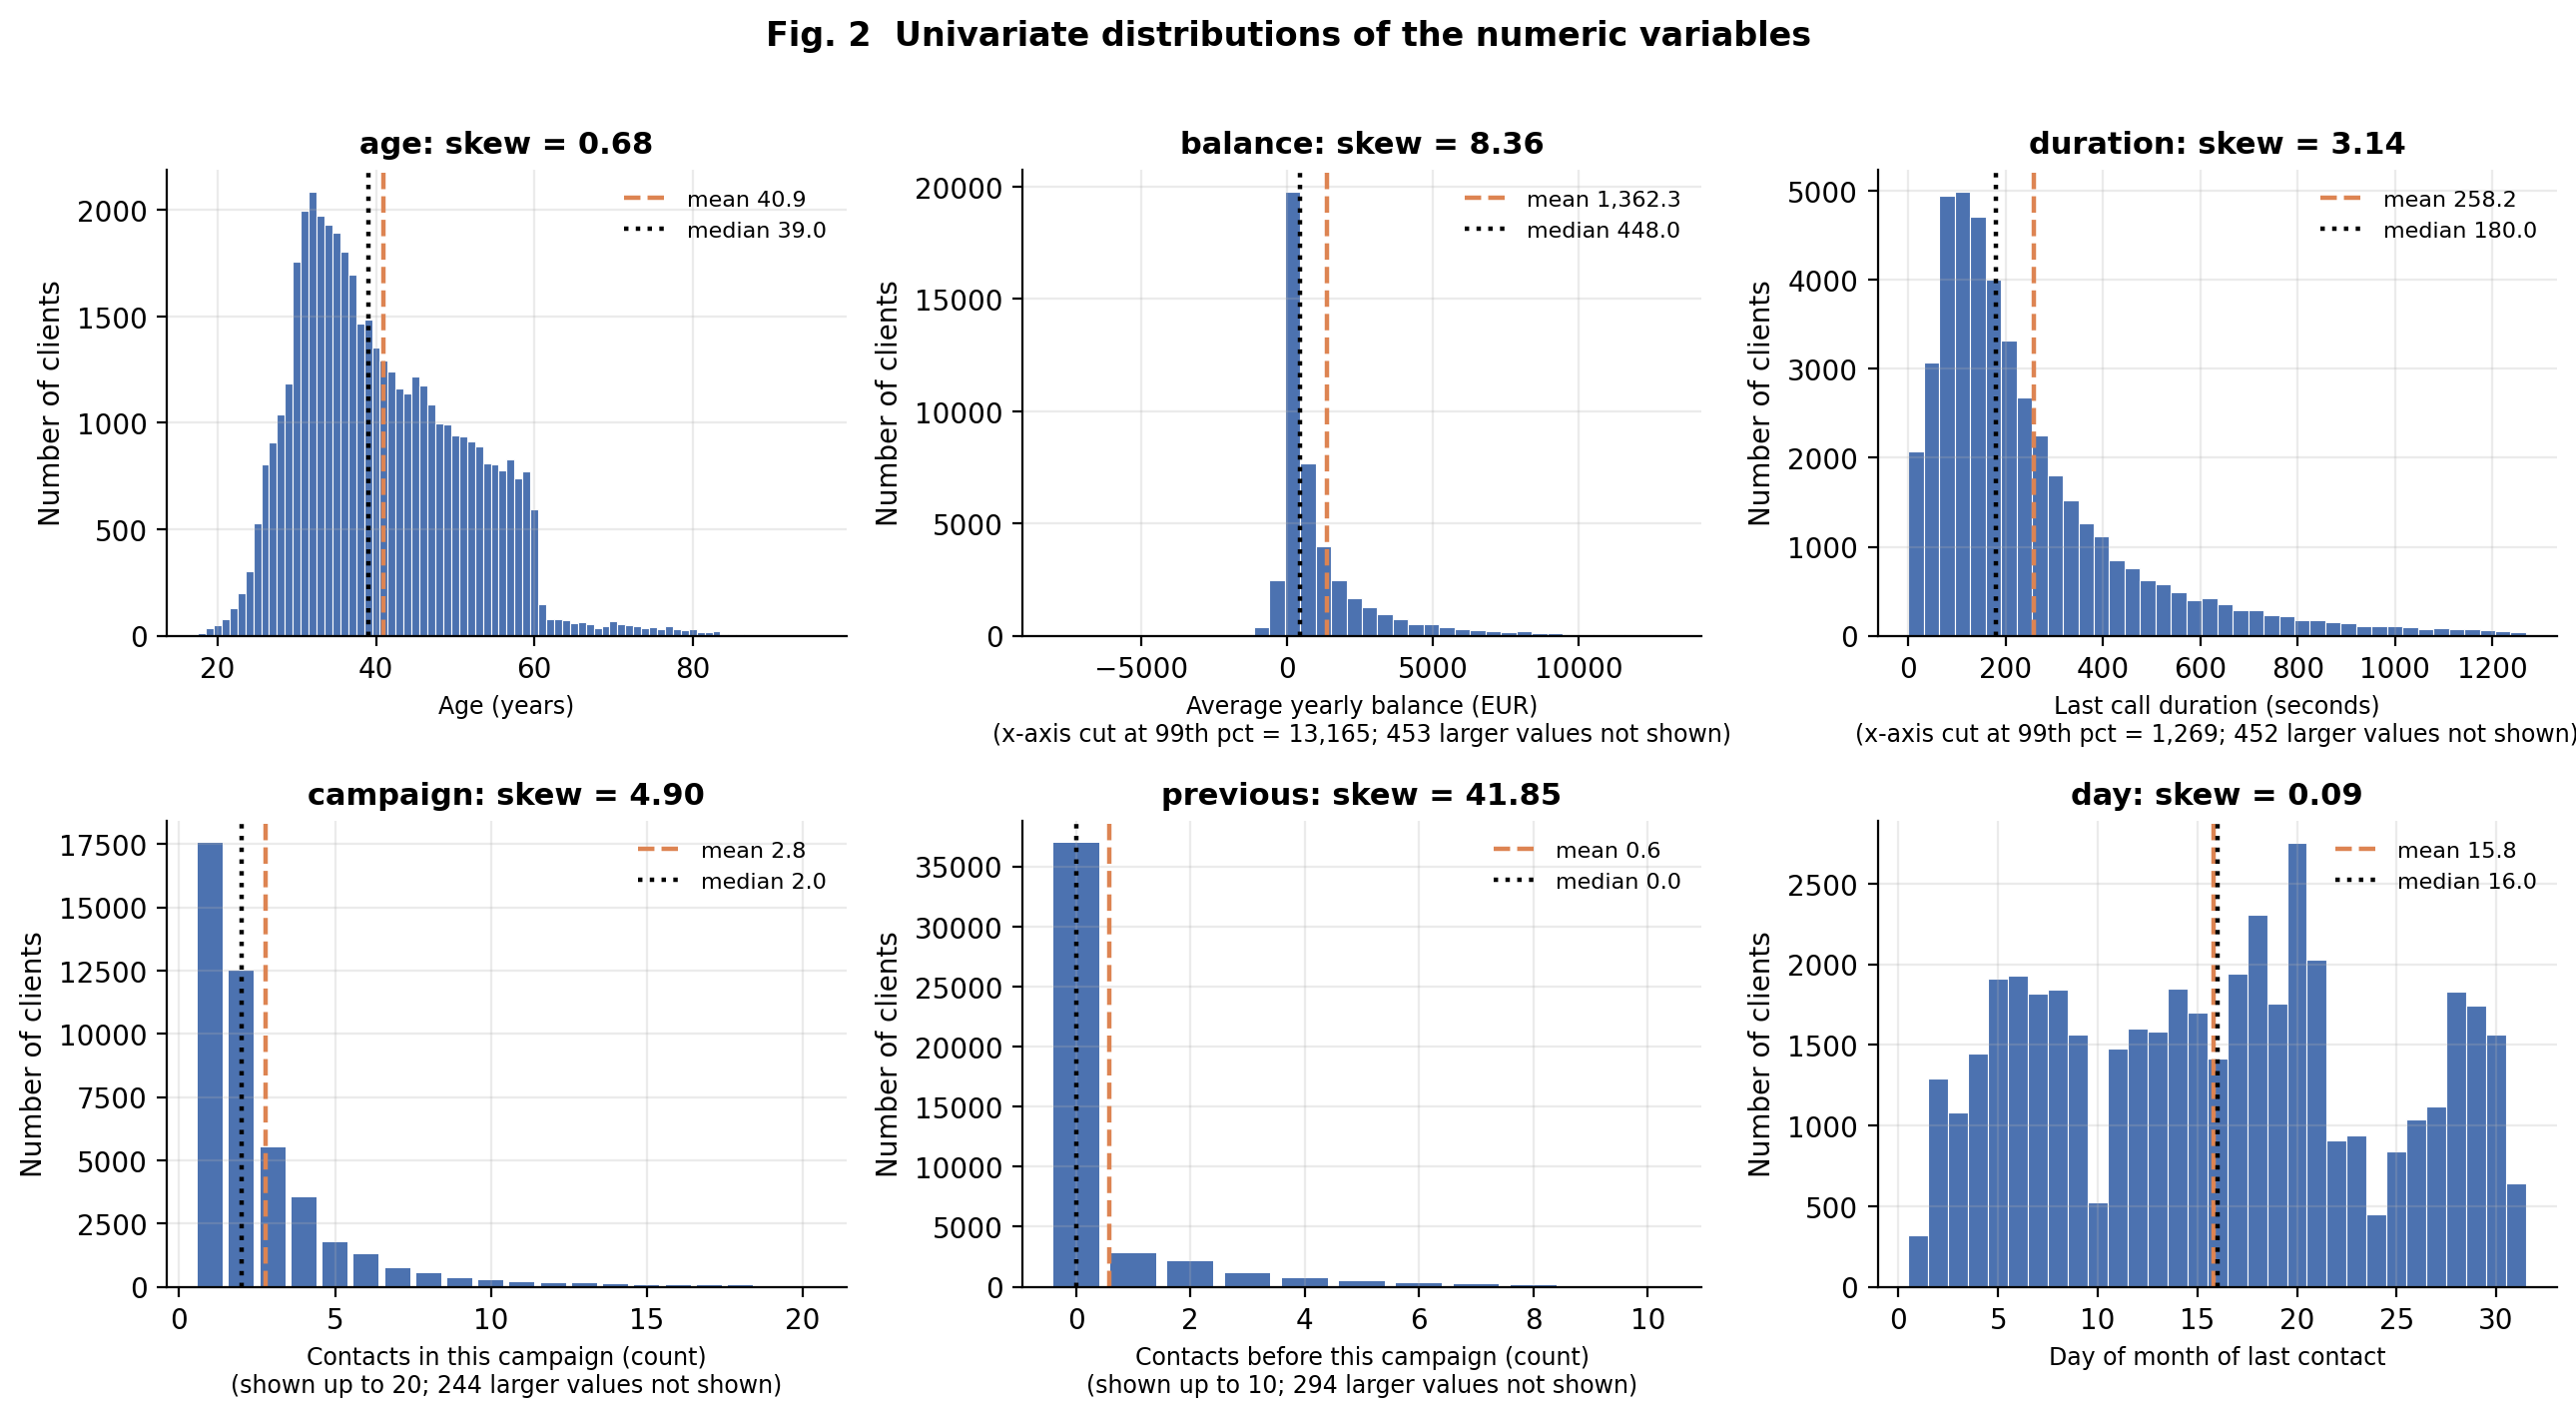

In [10]:
display(Image(str(FIG_DIR / 'fig02_numeric_histograms.png'), width=900))

**Figure 2 - Univariate distributions of the numeric variables**

| | |
|---|---|
| **Question** | What shape do the numeric variables have (symmetry, spread, tails, discreteness)? |
| **What it shows** | Histograms (bars for the two count variables) with the mean (dashed) and median (dotted). |
| **Why this chart** | Histograms expose skewness, modality and tail weight, which determine which transformations and robust statistics are needed. |
| **Variables** | age, balance, duration, campaign, previous, day. |
| **Finding** | age is mildly right-skewed (skew 0.68, mean 40.9 vs median 39). balance is extremely skewed (skew 8.36, excess kurtosis 141; mean EUR 1,362 vs median EUR 448). duration is right-skewed (skew 3.14; mean 258 s vs median 180 s). campaign (median 2, max 63) and previous (81.7% zeros, max 275) are zero/one-heavy counts with long tails. day is roughly flat (skew 0.09). |
| **Interpretation** | For balance, duration, campaign and previous the mean is a poor summary of a typical client; medians and quantiles are more representative, and log-type transformations are appropriate before modelling. The flat day-of-month profile suggests no strong calendar-day trend. |
| **Caveats** | The balance, duration, campaign and previous axes are truncated for readability (counts of hidden values are in the axis labels); the statistics in the panel titles use all records. |

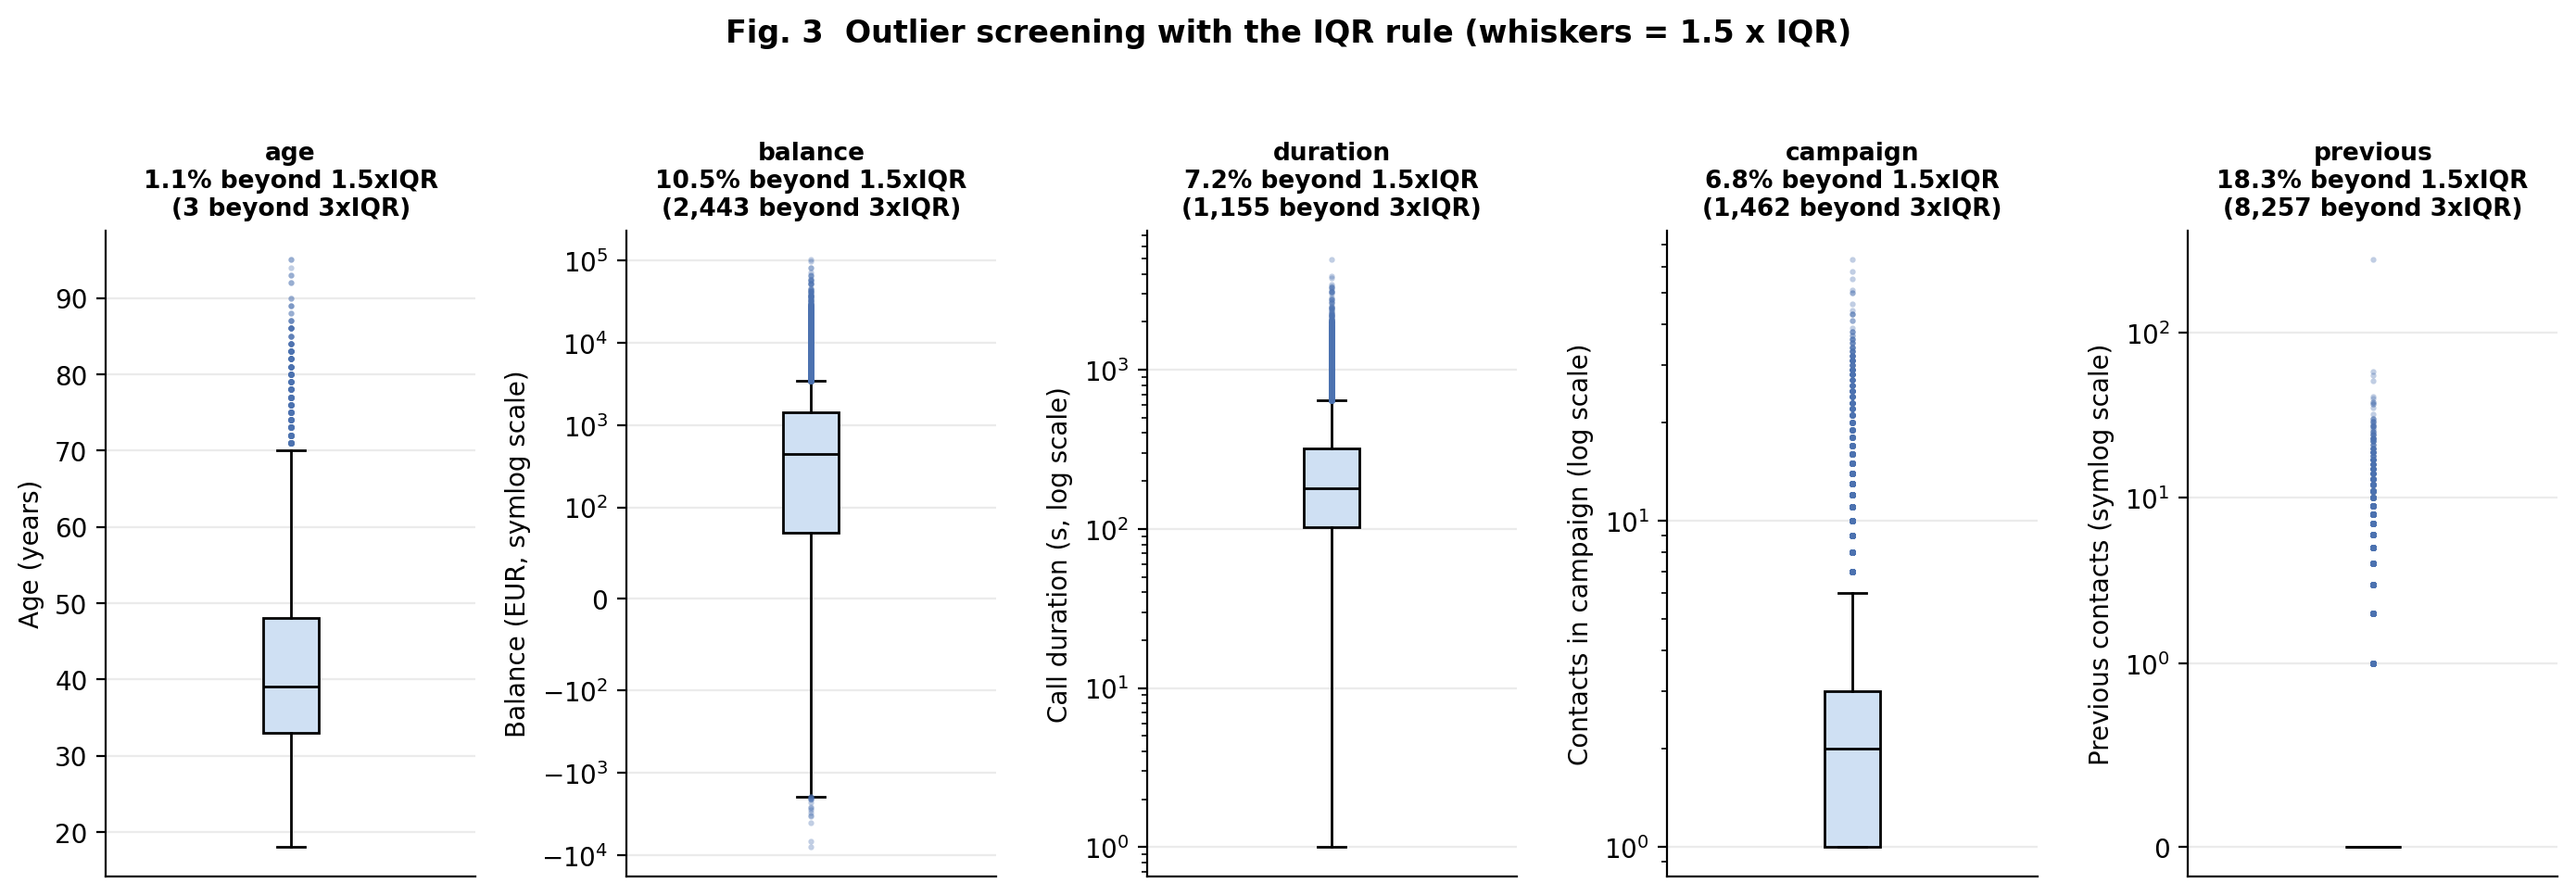

In [11]:
display(Image(str(FIG_DIR / 'fig03_outlier_boxplots.png'), width=900))

**Figure 3 - Outlier screening with the IQR rule**

| | |
|---|---|
| **Question** | How many observations lie far outside the bulk of each numeric variable, and are they errors? |
| **What it shows** | Boxplots with 1.5 x IQR whiskers on log / symmetric-log scales; titles give the share of flagged points. |
| **Why this chart** | Boxplots are the standard Tukey tool for outliers; log scales make heavy-tailed variables readable. |
| **Variables** | age, balance, duration, campaign, previous. |
| **Finding** | Flagged by 1.5 x IQR: balance 10.5% (4,729 records), duration 7.2%, campaign 6.8%, age 1.1%, previous 18.3% (degenerate: IQR = 0). The largest values are previous = 275, campaign = 63, balance = EUR 102,127, duration = 4,918 s. |
| **Interpretation** | These are plausible behaviours (wealthy clients, long conversations, persistent re-dialling) rather than obvious errors, and subscribers cluster among long calls, so deleting them would discard signal. Decision: retain all records; compress tails with a signed-log transform (balance) and cap-then-log (campaign, previous, at the training-set 99th percentile). The single previous = 275 record is the only value that looks like a possible entry error and is neutralised by the cap. |
| **Caveats** | The IQR rule assumes roughly symmetric data; for skewed variables it flags many legitimate values. Negative balances (overdrafts) are valid and are not outliers in the cleaning sense. |

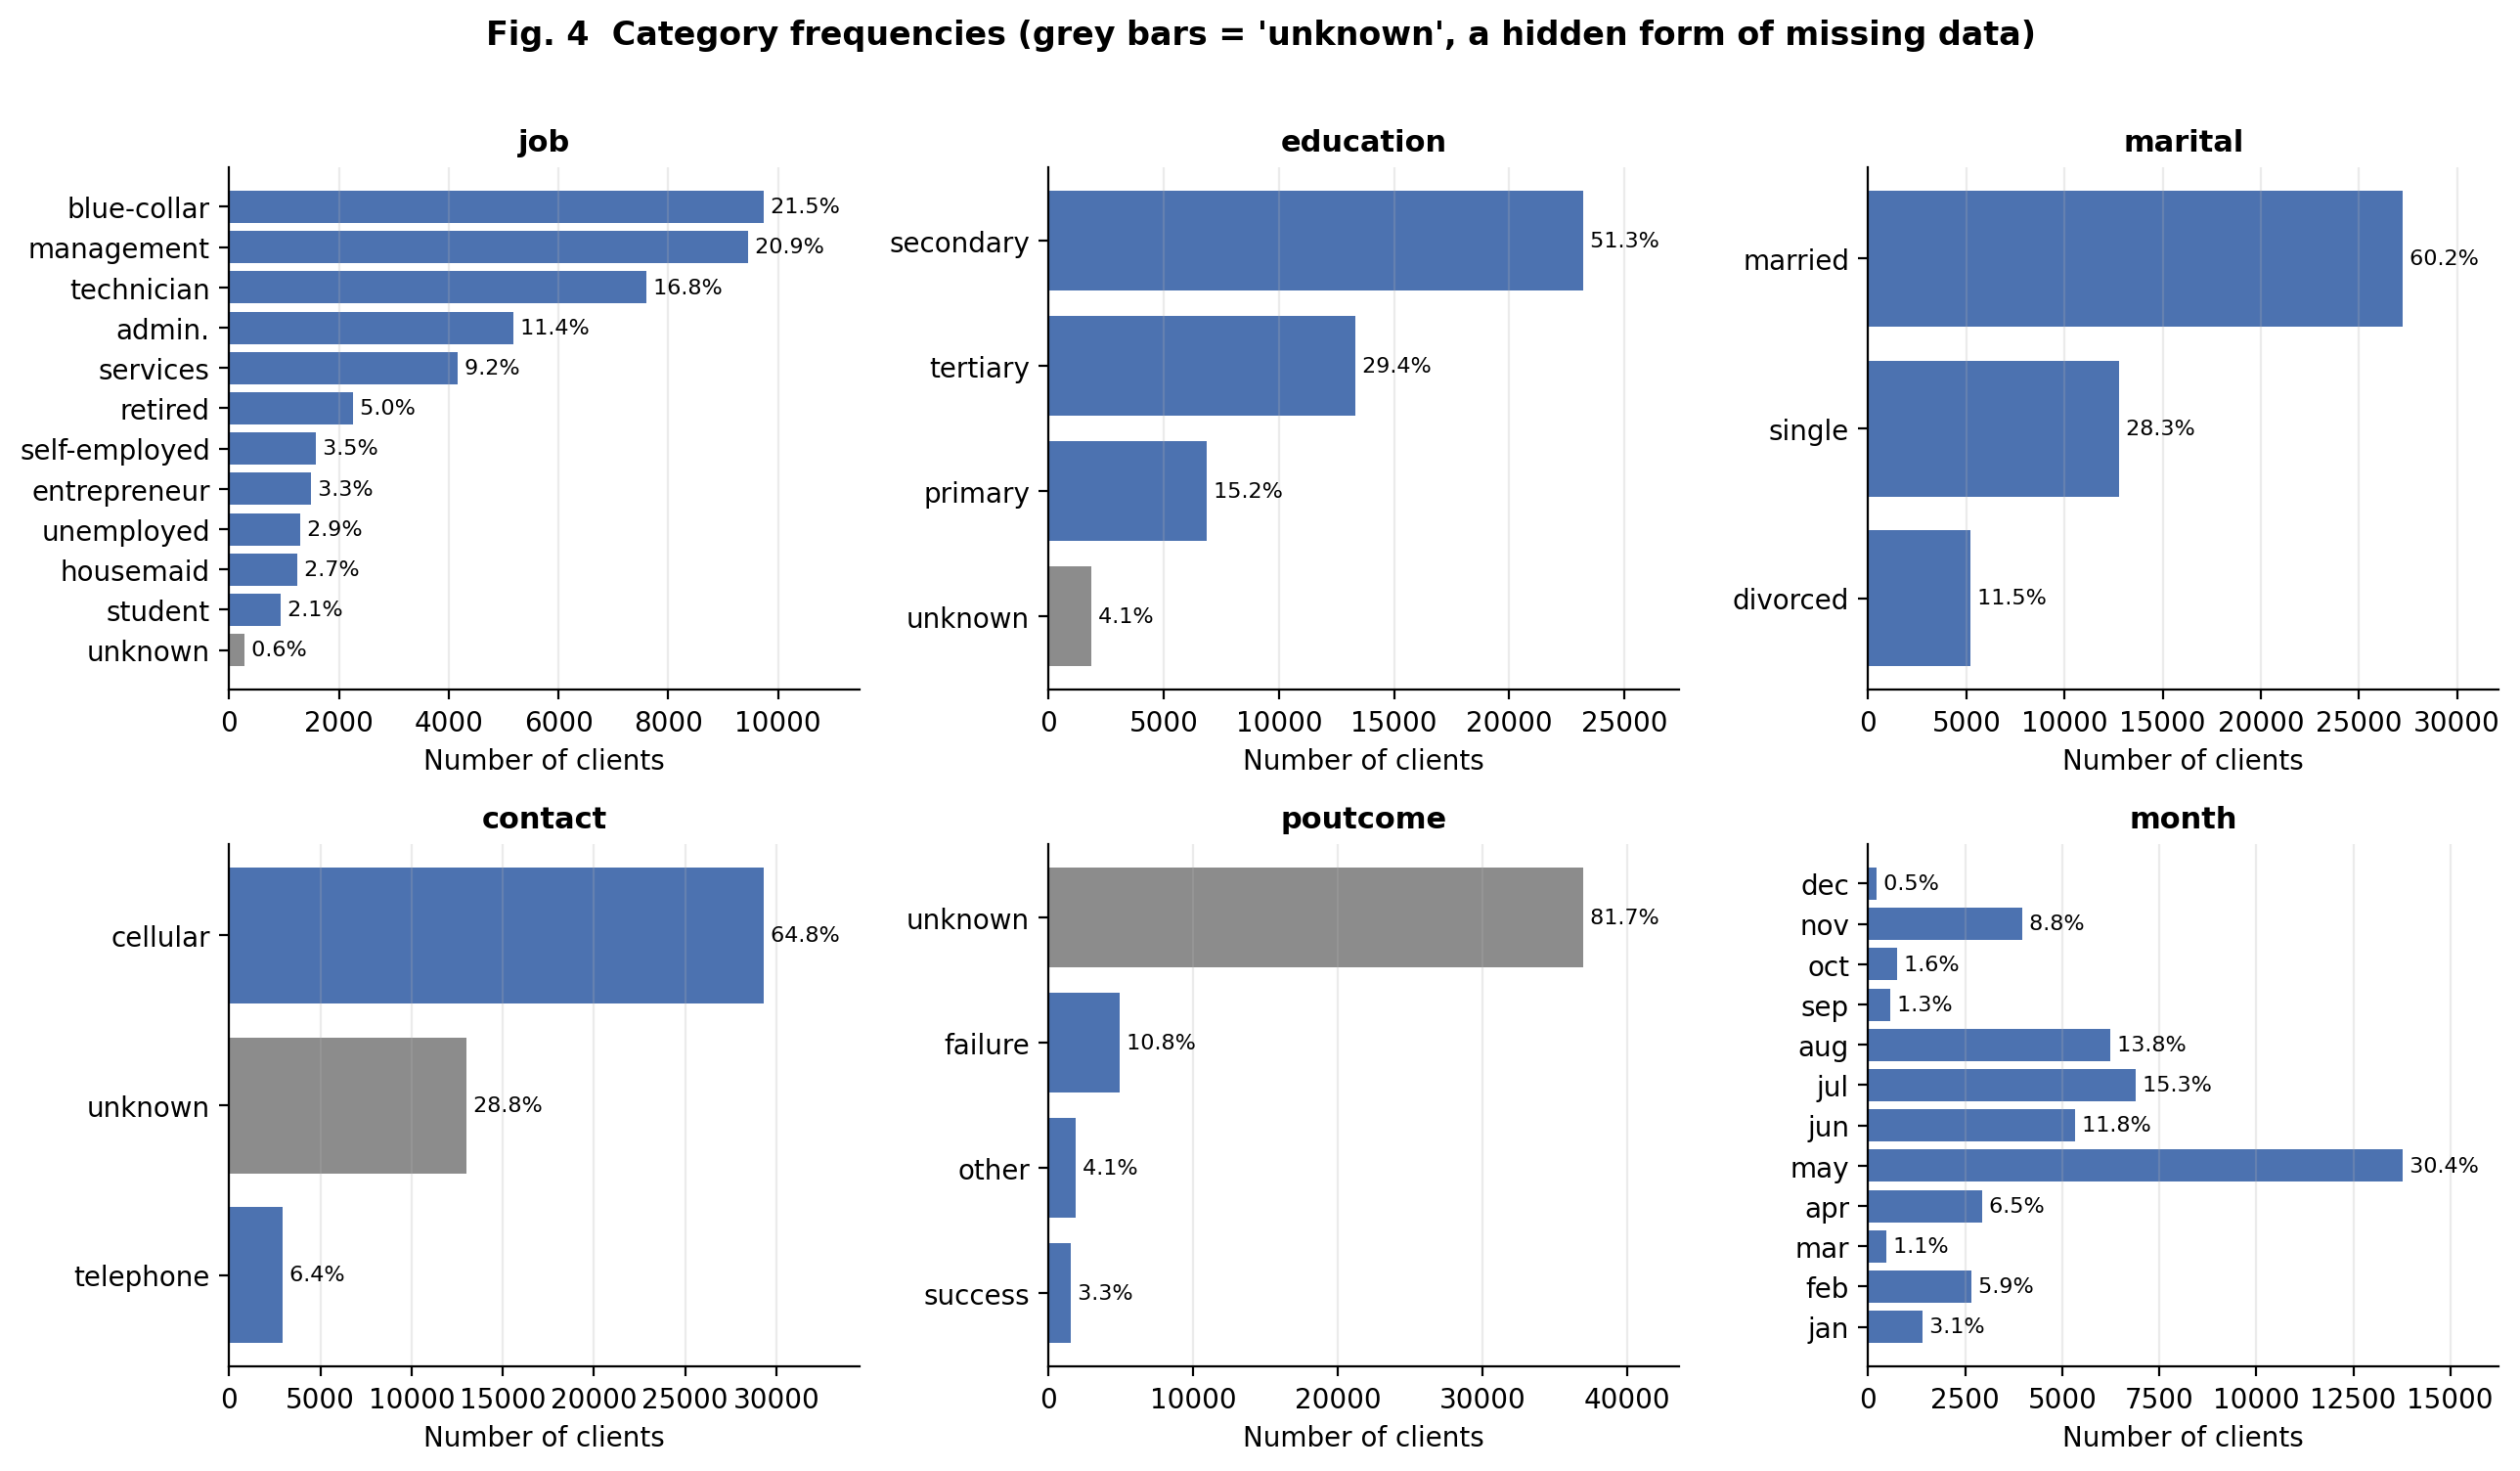

In [12]:
display(Image(str(FIG_DIR / 'fig04_categorical_counts.png'), width=900))

**Figure 4 - Category frequencies and hidden missing data**

| | |
|---|---|
| **Question** | How are the categorical variables distributed, and where is information hidden behind 'unknown'? |
| **What it shows** | Horizontal bars of category shares; 'unknown' levels are grey. |
| **Why this chart** | Bar charts are the correct encoding for nominal variables; ordering by size (or calendar order for month) aids comparison. |
| **Variables** | job, education, marital, contact, poutcome, month. |
| **Finding** | The file has no NaN cells, yet 'unknown' accounts for 81.7% of poutcome, 28.8% of contact, 4.1% of education and 0.6% of job. May alone holds 30.4% of all calls; married clients are 60.2%; blue-collar and management jobs together are 42.4%. |
| **Interpretation** | poutcome = 'unknown' (36,959 clients) coincides with pdays = -1 ('never contacted before', 36,954 clients) up to 5 records, so it is structural, not random, missingness. Therefore 'unknown' is kept as its own category instead of being imputed with the mode. |
| **Caveats** | The calls are heavily concentrated in a few months, so the client mix is not representative of the whole year. |

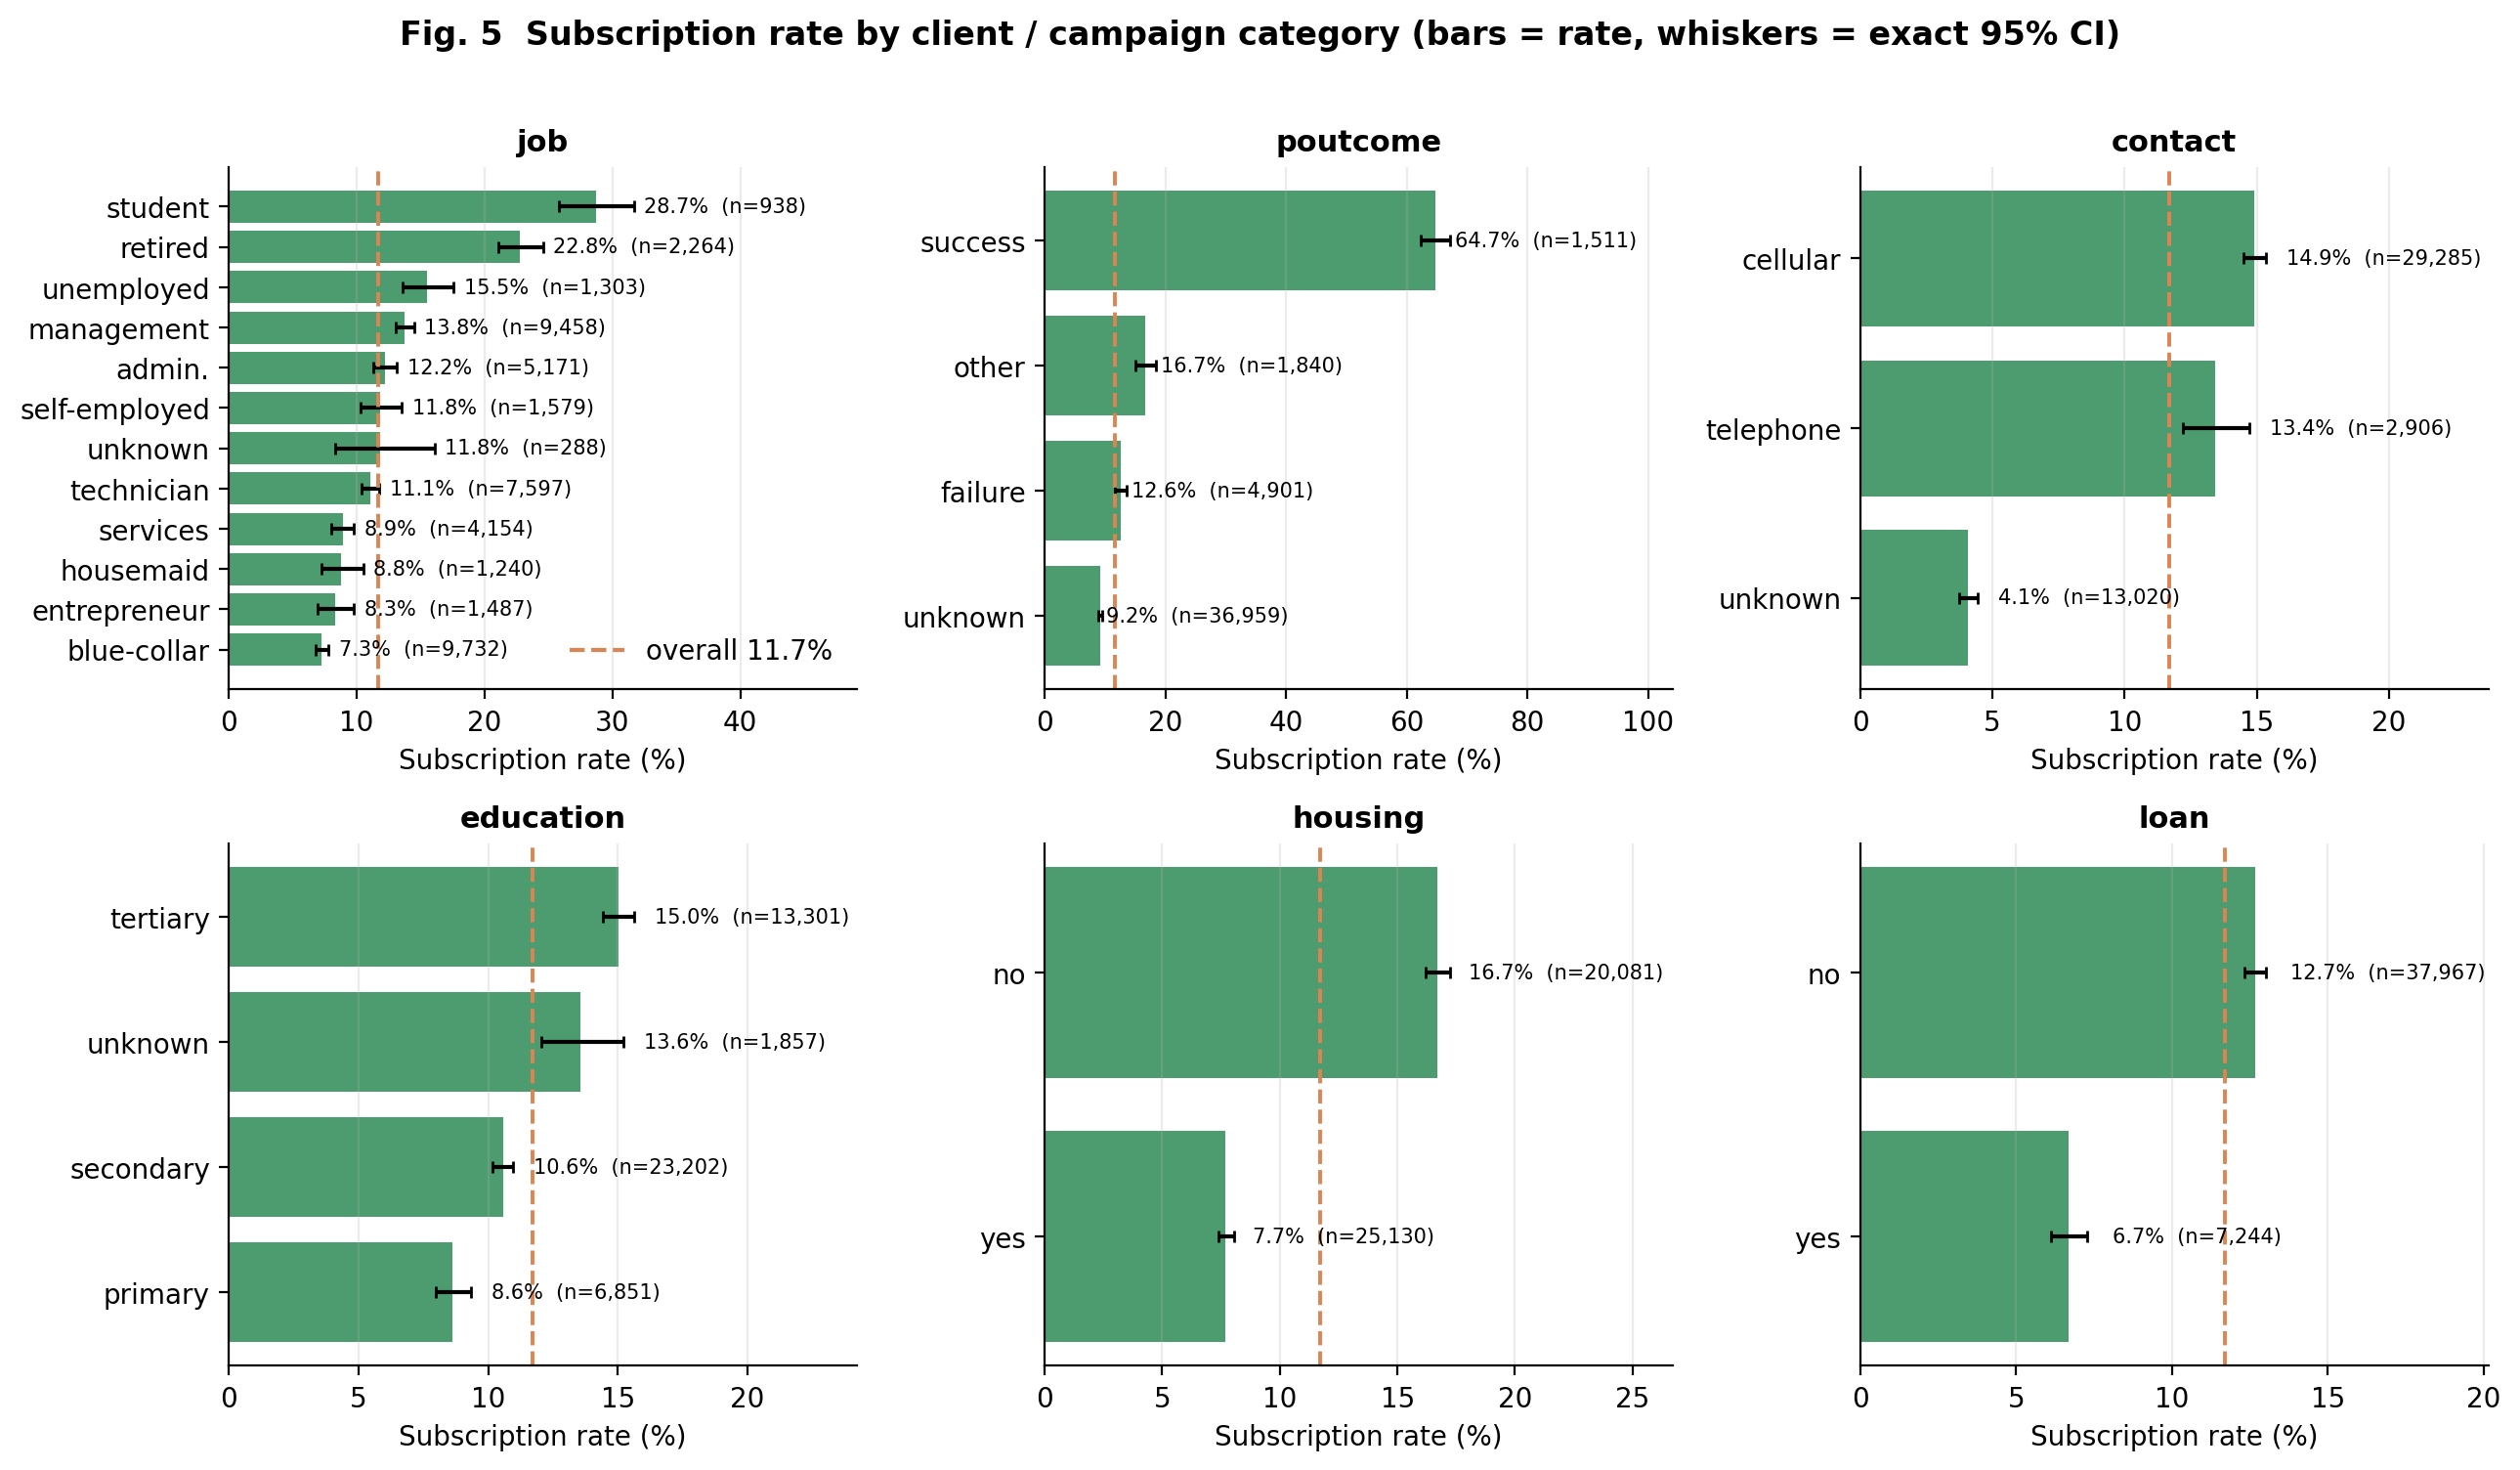

In [13]:
display(Image(str(FIG_DIR / 'fig05_rate_by_category.png'), width=900))

**Figure 5 - Subscription rate by category**

| | |
|---|---|
| **Question** | Which client and campaign categories convert more or less often than average? |
| **What it shows** | Subscription rate per level with exact (Clopper-Pearson) 95% CIs, sorted; dashed line = overall rate. |
| **Why this chart** | Showing rates with confidence intervals and n prevents over-reading small groups; counts alone (Fig. 4) would not show conversion. |
| **Variables** | job, poutcome, contact, education, housing, loan vs. y. |
| **Finding** | Previous success is the standout: poutcome = success converts at 64.7% (n = 1,511) versus 9.2% for unknown. Students (28.7%) and retired clients (22.8%) exceed blue-collar (7.3%). Unknown contact type converts at 4.1% vs 14.9% (cellular). Clients without a housing loan subscribe at 16.7% vs 7.7% with one; without a personal loan 12.7% vs 6.7%. |
| **Interpretation** | Existing positive relationships and clients with fewer credit commitments are the most receptive; a bank could prioritise them. These are descriptive associations: they do not show that a loan causes refusal. |
| **Caveats** | These are marginal rates, not adjusted for each other. contact = unknown is concentrated in June (85% of June calls) and May (58%), so it partly reflects timing. |

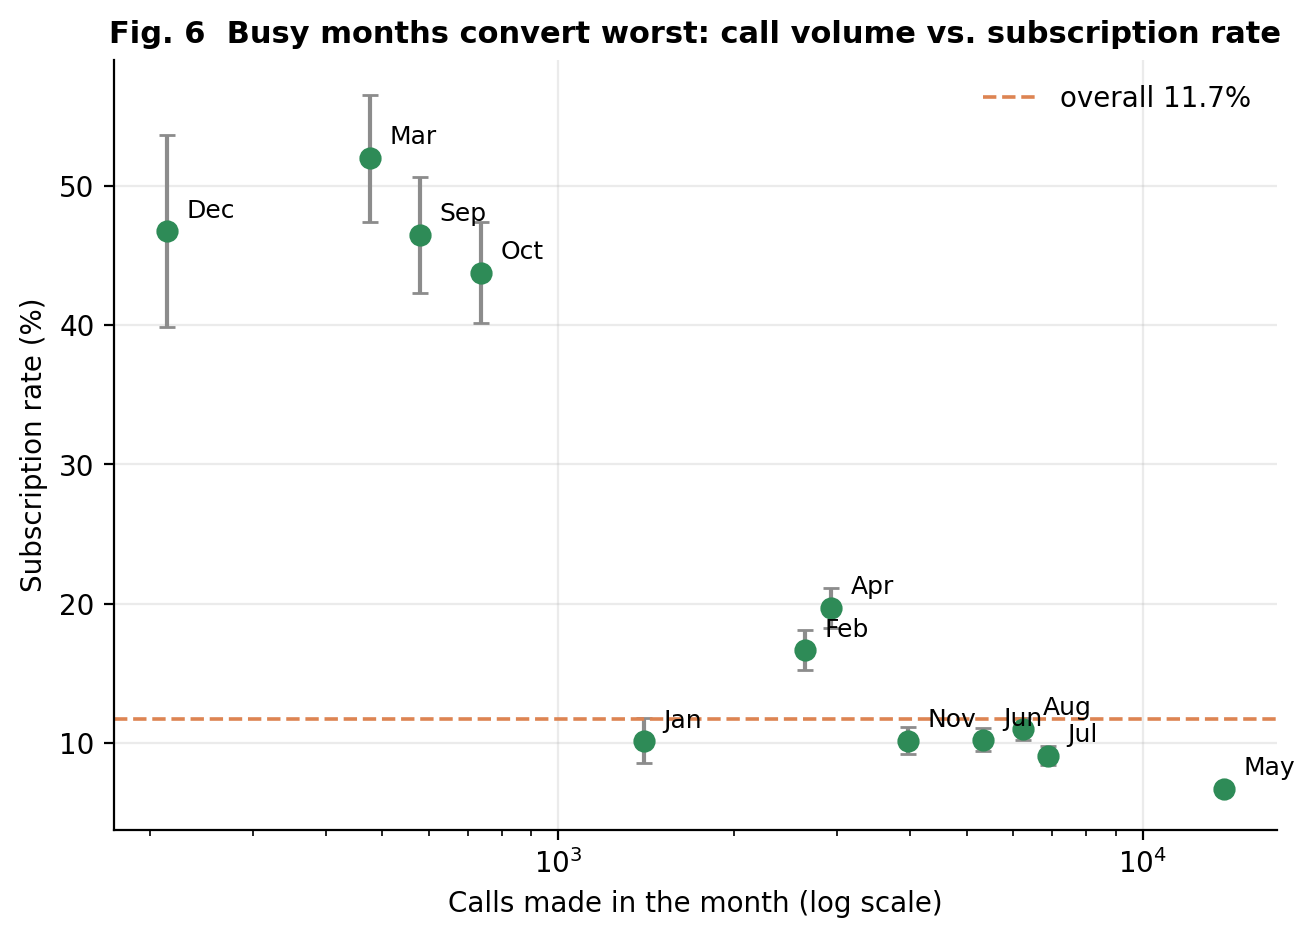

In [14]:
display(Image(str(FIG_DIR / 'fig06_month_volume_vs_rate.png'), width=900))

**Figure 6 - Call volume versus subscription rate by month**

| | |
|---|---|
| **Question** | Is the success rate constant over the calendar, as a single Bernoulli/binomial model would assume? |
| **What it shows** | One point per month: calls made (log x-axis) against subscription rate with 95% CI. |
| **Why this chart** | A scatter of volume against rate exposes the relationship between effort and outcome that a plain monthly bar chart hides. |
| **Variables** | month, y. |
| **Finding** | May has 13,766 calls but the lowest rate (6.7%); Mar, Sep, Oct, Dec have only 2,008 calls in total, with rates of 44%-52%. Monthly rates range from 6.7% to 52.0%; homogeneity chi-square(11) = 3062, p < 0.001, Cramer's V = 0.26. |
| **Interpretation** | The success probability is clearly not the same in every month, so one common Bernoulli/binomial parameter is inadequate and month must be a model input. Busy months are the least productive, consistent with mass-calling broad lists versus selectively calling warmer clients. |
| **Caveats** | The data have no year field and span 2008-2010, so month mixes campaign phases. Low-volume months were probably selectively targeted (88% of May clients hold housing loans vs 18-24% in Mar/Sep/Oct/Dec), so this is not evidence that calling less causes higher conversion. |

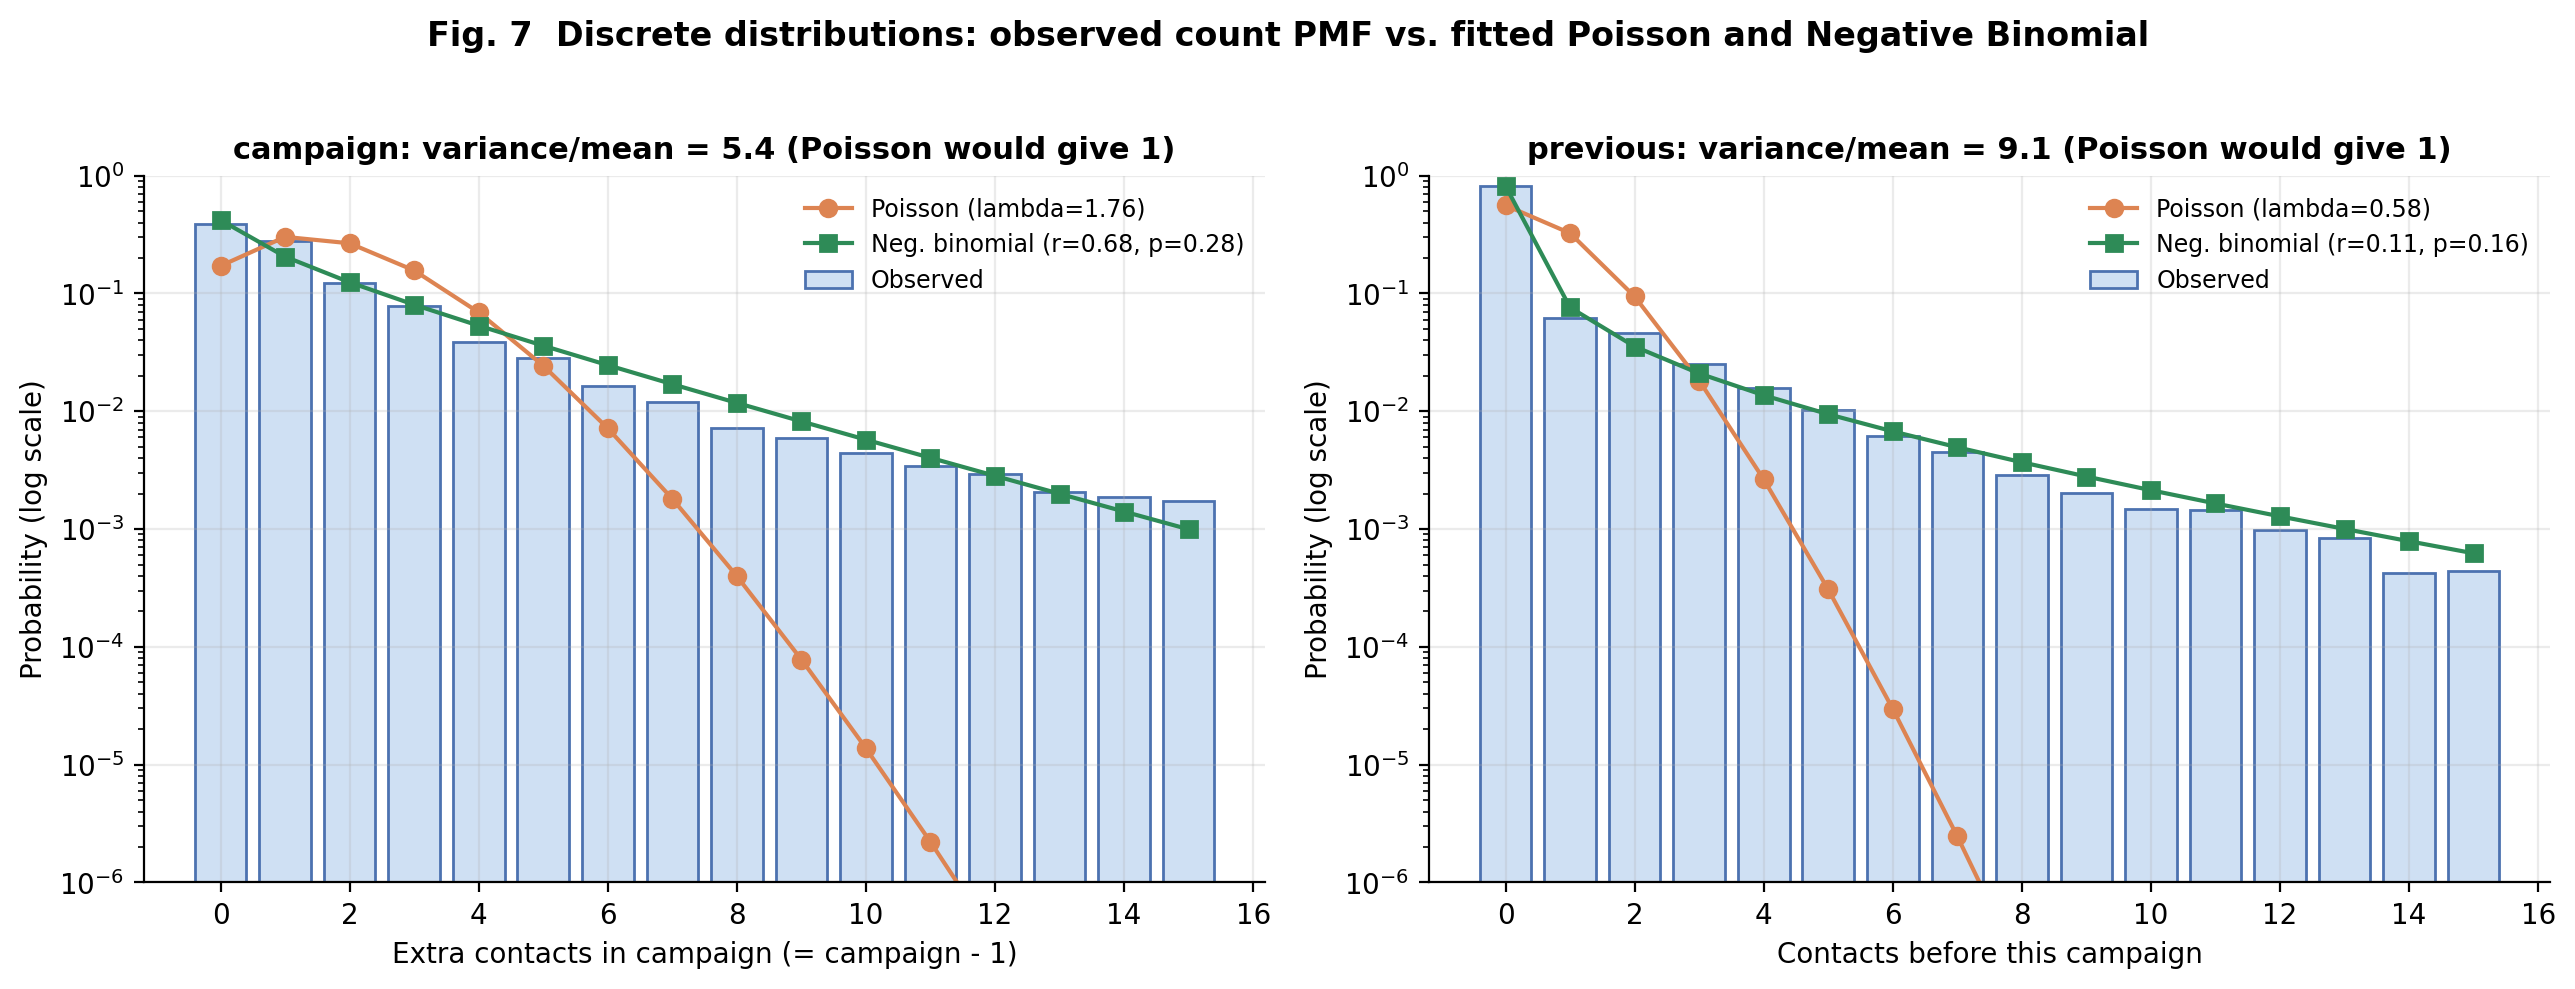

In [15]:
display(Image(str(FIG_DIR / 'fig07_count_distribution.png'), width=900))

**Figure 7 - Discrete distributions: Poisson versus Negative Binomial**

| | |
|---|---|
| **Question** | Can the number of contacts be modelled as Poisson events, or is the data over-dispersed? |
| **What it shows** | Observed probability mass function (bars) against fitted Poisson and Negative Binomial PMFs, log-scaled y-axis. |
| **Why this chart** | Overlaying fitted PMFs on a log axis is the clearest way to compare tail behaviour, which is where count models usually fail. |
| **Variables** | campaign - 1 (extra contacts in this campaign), previous. |
| **Finding** | campaign - 1: mean 1.76, variance 9.60, variance/mean = 5.4. Zeros: observed 38.8%, Poisson 17.1%, Negative Binomial 42.0%. P(>= 10 extra contacts): observed 2.65%, Poisson 0.0016%, NB 1.94%. AIC: Poisson 220,368 vs NB 162,240. previous: variance/mean = 9.1, observed zeros 81.7% vs Poisson 56.0% vs NB 81.6%. |
| **Interpretation** | The Poisson assumption (variance = mean, constant event rate) fails badly. The Negative Binomial (a Poisson-Gamma mixture, allowing client-to-client differences in contactability) captures the heavy tail and the excess zeros far better (AIC lower by 58,128). Even so, chi-square goodness-of-fit still rejects it (campaign: chi2 = 1786, df = 7, p < 0.001), so it is a reasonable approximation, not an exact model. |
| **Caveats** | With n = 45,211 any imperfect model is rejected; the relevant question is practical closeness. Contact counts are produced by bank policy (stop rules), so independence is questionable. previous is zero-inflated (a hurdle model would be a natural next step). |

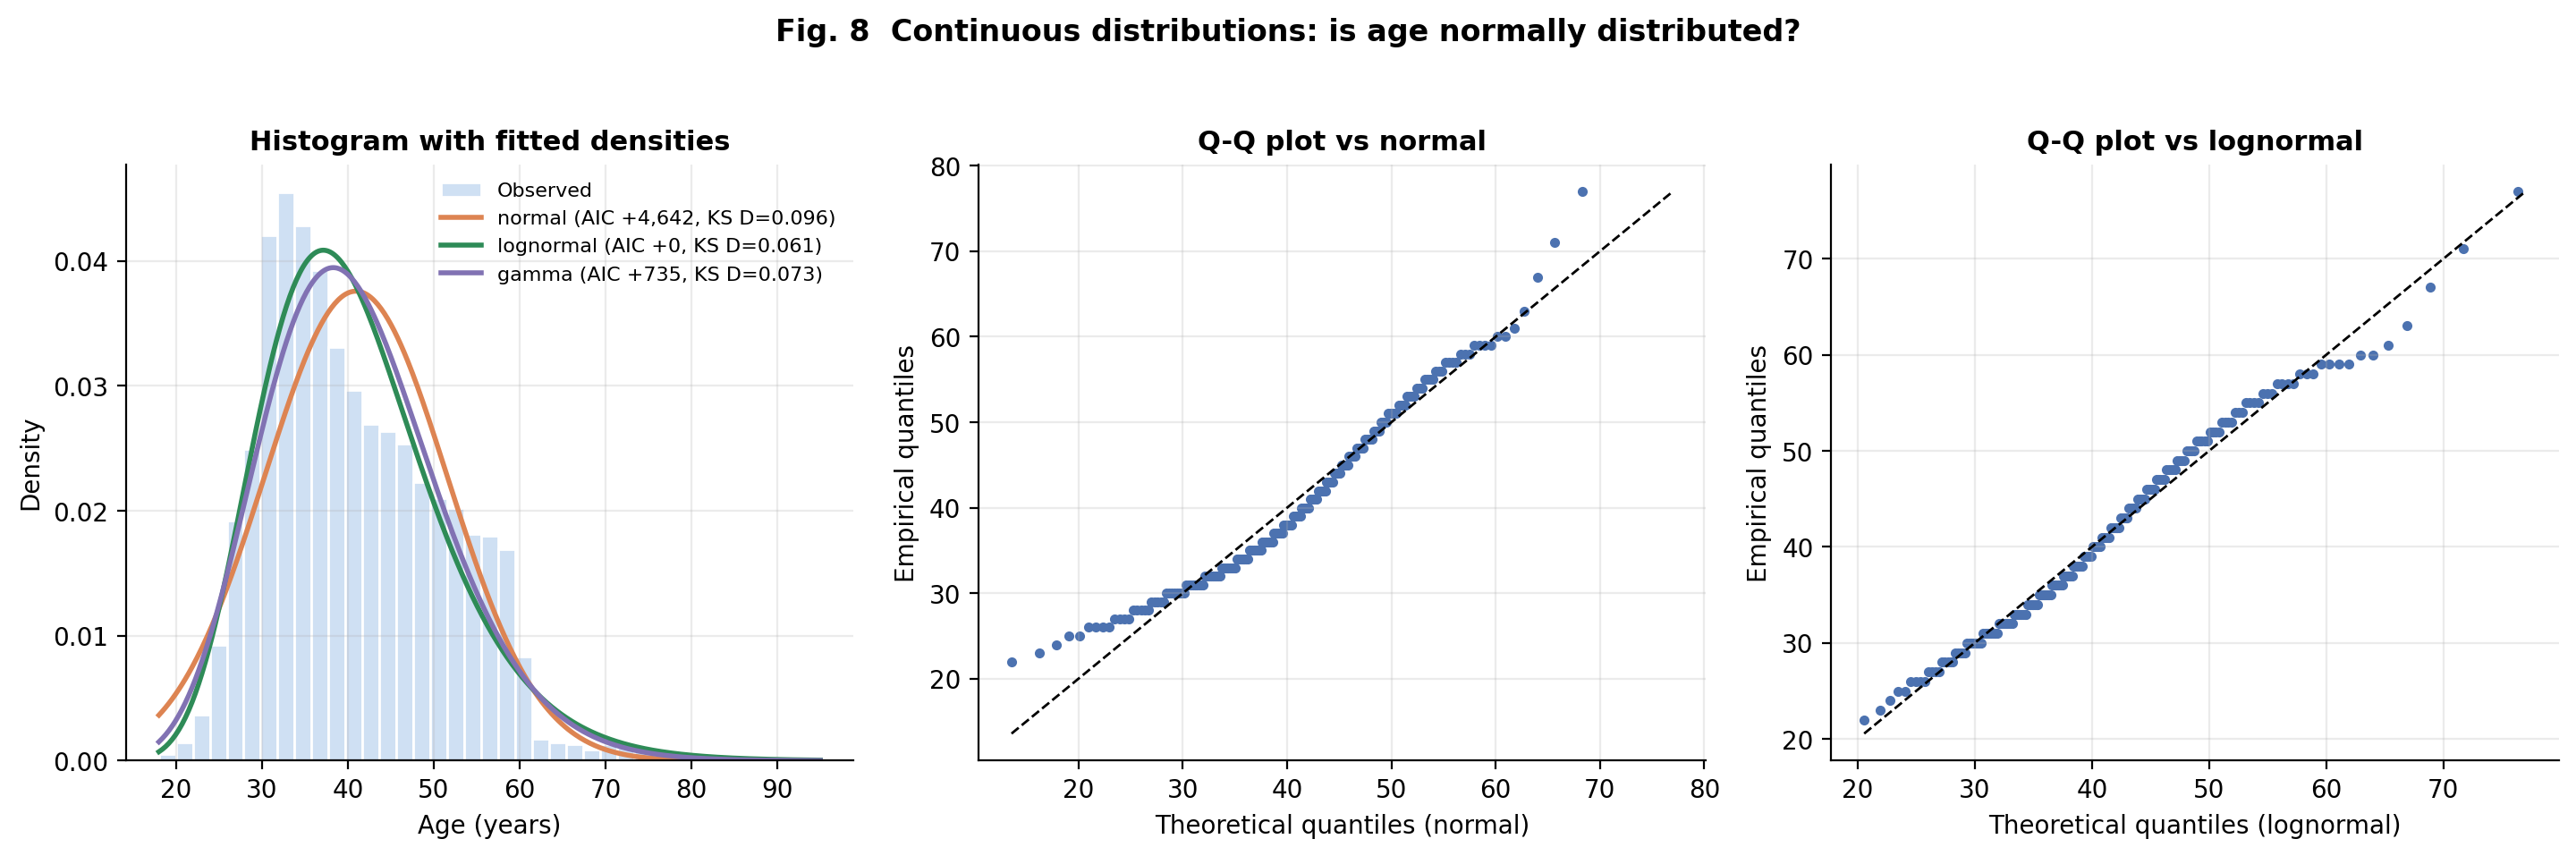

In [16]:
display(Image(str(FIG_DIR / 'fig08_age_fits.png'), width=900))

**Figure 8 - Continuous distributions: is age normal?**

| | |
|---|---|
| **Question** | Is age approximately normally distributed, and if not, which family is closer? |
| **What it shows** | Histogram with fitted Normal, Lognormal and Gamma densities (left) and Q-Q plots against Normal and Lognormal (centre, right). |
| **Why this chart** | Density overlays show body fit; Q-Q plots reveal tail departures that overlays hide. Fit quality is judged with AIC and the KS distance, not by eye. |
| **Variables** | age. |
| **Finding** | Normality is rejected (D'Agostino K2 = 3067, p < 0.001; Shapiro-Wilk W = 0.962 on a 5,000 sample, p < 0.001); skew = 0.68. AIC ranks Lognormal best (Gamma +735, Normal +4,642); KS distance D: Normal 0.096, Gamma 0.073, Lognormal 0.061. |
| **Interpretation** | Age is right-skewed with a lower bound at 18 and a long upper tail, so the Normal is a poor description (largest CDF gap 9.6%). Lognormal is the best of the three but still leaves a maximum CDF gap of 6.1%, so no simple family is accurate and the empirical distribution should be used for inference. |
| **Caveats** | Fits fix the location at 0; a shifted distribution (e.g. starting at 18) might fit better. KS p-values with estimated parameters are only indicative, so D and AIC are reported as effect sizes. |

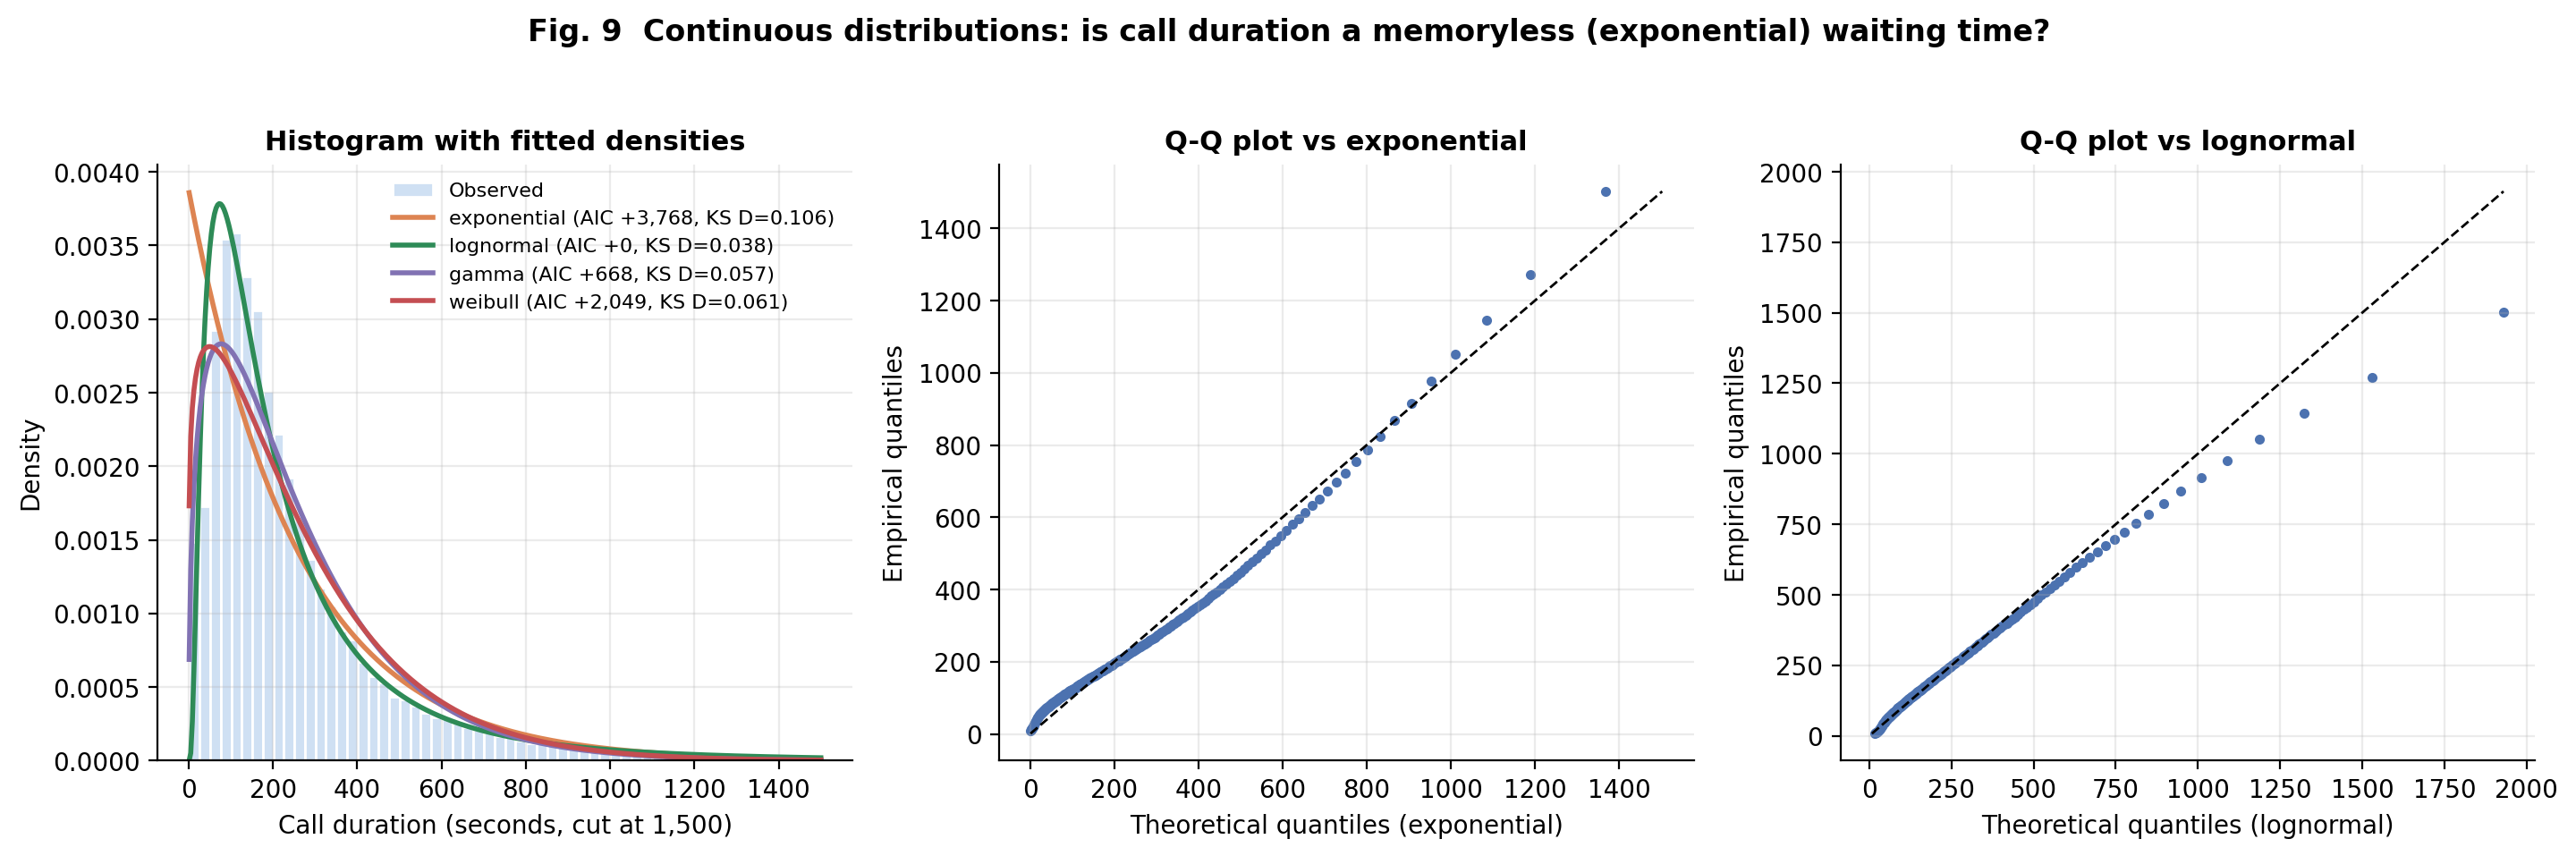

In [17]:
display(Image(str(FIG_DIR / 'fig09_duration_fits.png'), width=900))

**Figure 9 - Continuous distributions: is call duration exponential?**

| | |
|---|---|
| **Question** | Does call duration behave like a memoryless (exponential) waiting time? |
| **What it shows** | Histogram with fitted Exponential, Lognormal, Gamma and Weibull densities (left) and Q-Q plots against Exponential and Lognormal. |
| **Why this chart** | Durations are the textbook use-case for the exponential model, so the assumption is tested explicitly rather than assumed. |
| **Variables** | duration (seconds; 45,208 calls with duration > 0). |
| **Finding** | AIC ranks Lognormal best (Gamma +668, Weibull +2,049, Exponential +3,768). KS distance D: Lognormal 0.038, Gamma 0.057, Weibull 0.061, Exponential 0.106. Calls shorter than 30 s: observed 4.3% vs 11.0% expected under the fitted Exponential. |
| **Interpretation** | The exponential model overstates very short calls (its density peaks at zero) whereas real calls have a mode near 100 s: people rarely hang up instantly but converse for a typical length, so the process is not memoryless. The exponential's median (179 s) happens to match the observed median (180 s), a good reminder that matching one summary is not goodness of fit; the Q-Q plot against the Exponential looks deceptively close in the upper tail while D = 0.106 and the AIC gap show the body is wrong. |
| **Caveats** | Only the last call to each client is recorded and duration is not known before a call, so it cannot be used for pre-call prediction (see Section 7). |

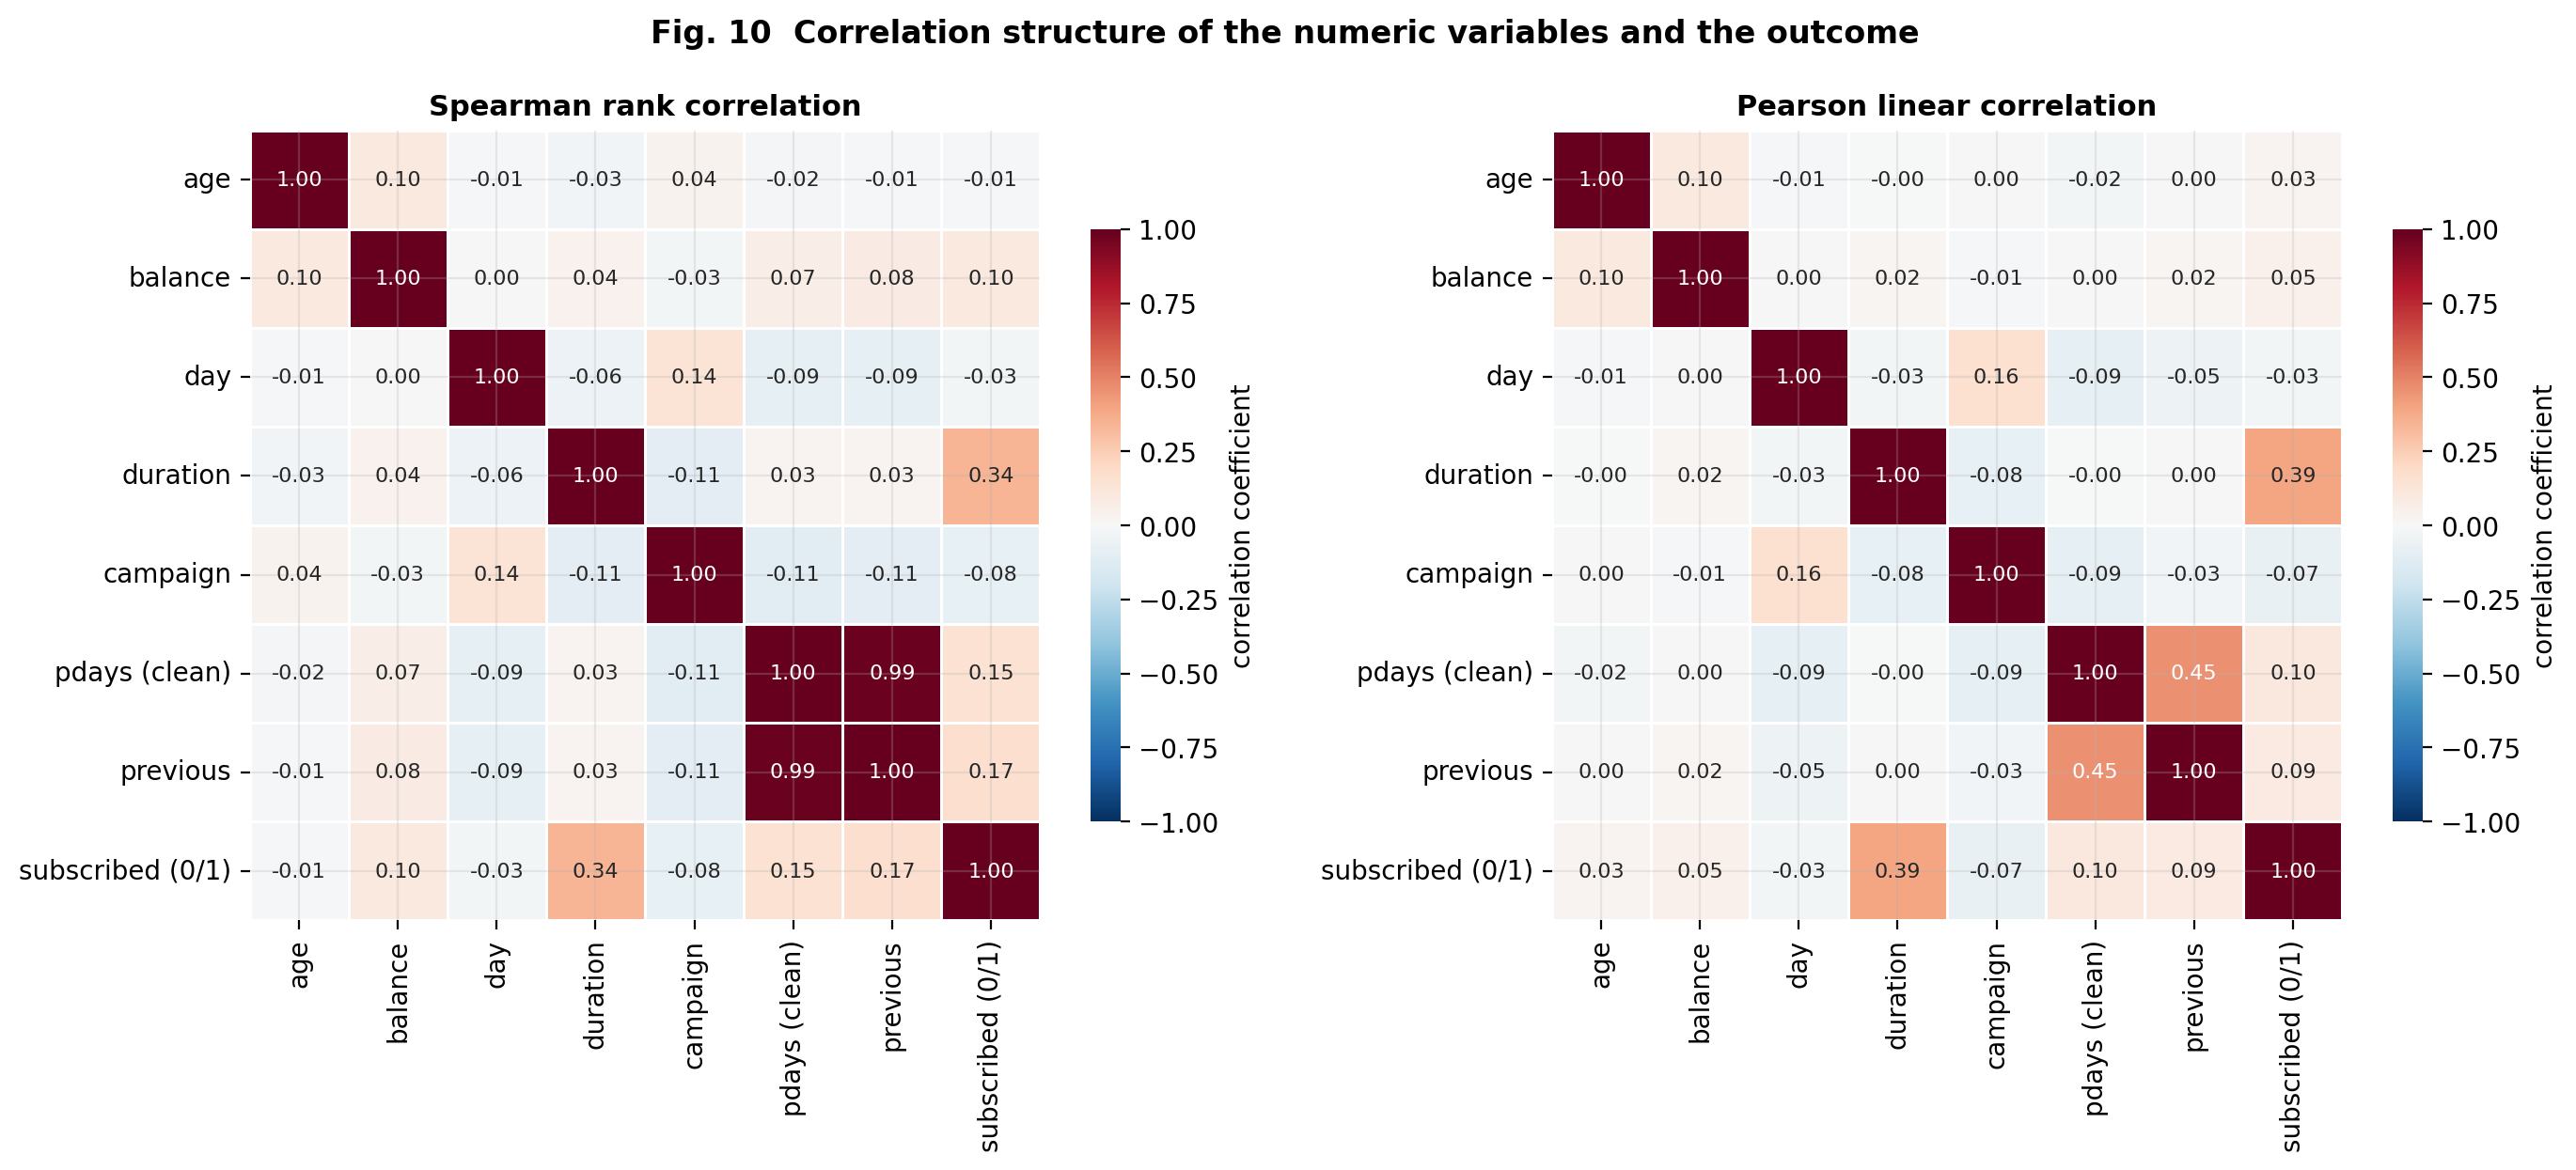

In [18]:
display(Image(str(FIG_DIR / 'fig10_correlation_heatmaps.png'), width=900))

**Figure 10 - Correlation heatmaps (Spearman and Pearson)**

| | |
|---|---|
| **Question** | Which numeric variables move together, and which relate to the outcome? |
| **What it shows** | Annotated correlation matrices; Spearman (rank-based, monotonic) beside Pearson (linear). |
| **Why this chart** | The two measures are shown together because the variables are heavily skewed: Spearman is robust to the tails, and any gap between the two reveals outlier influence. |
| **Variables** | age, balance, day, duration, campaign, pdays (clean), previous, subscribed (0/1). |
| **Finding** | With the outcome: duration rho = 0.34 (Pearson 0.39), previous 0.17, pdays 0.15, balance 0.10, campaign -0.08, age -0.01. Among predictors, only previous-pdays is strong (rho = 0.99); the next largest \|rho\| is campaign-day = 0.14. |
| **Interpretation** | All single-variable associations with the outcome are weak to moderate (\|rho\| <= 0.34); duration is strongest but unavailable before the call. previous and pdays are nearly redundant, which is why one of them is dropped from the logistic regression (VIF 1005 -> 5.2). balance has Pearson 0.05 but Spearman 0.10: extreme values weaken the linear measure. |
| **Caveats** | Correlation is not causation, and a coefficient near zero does not rule out a non-monotonic relationship: age has rho = -0.01 yet a strong U-shaped pattern (Fig. 13). |

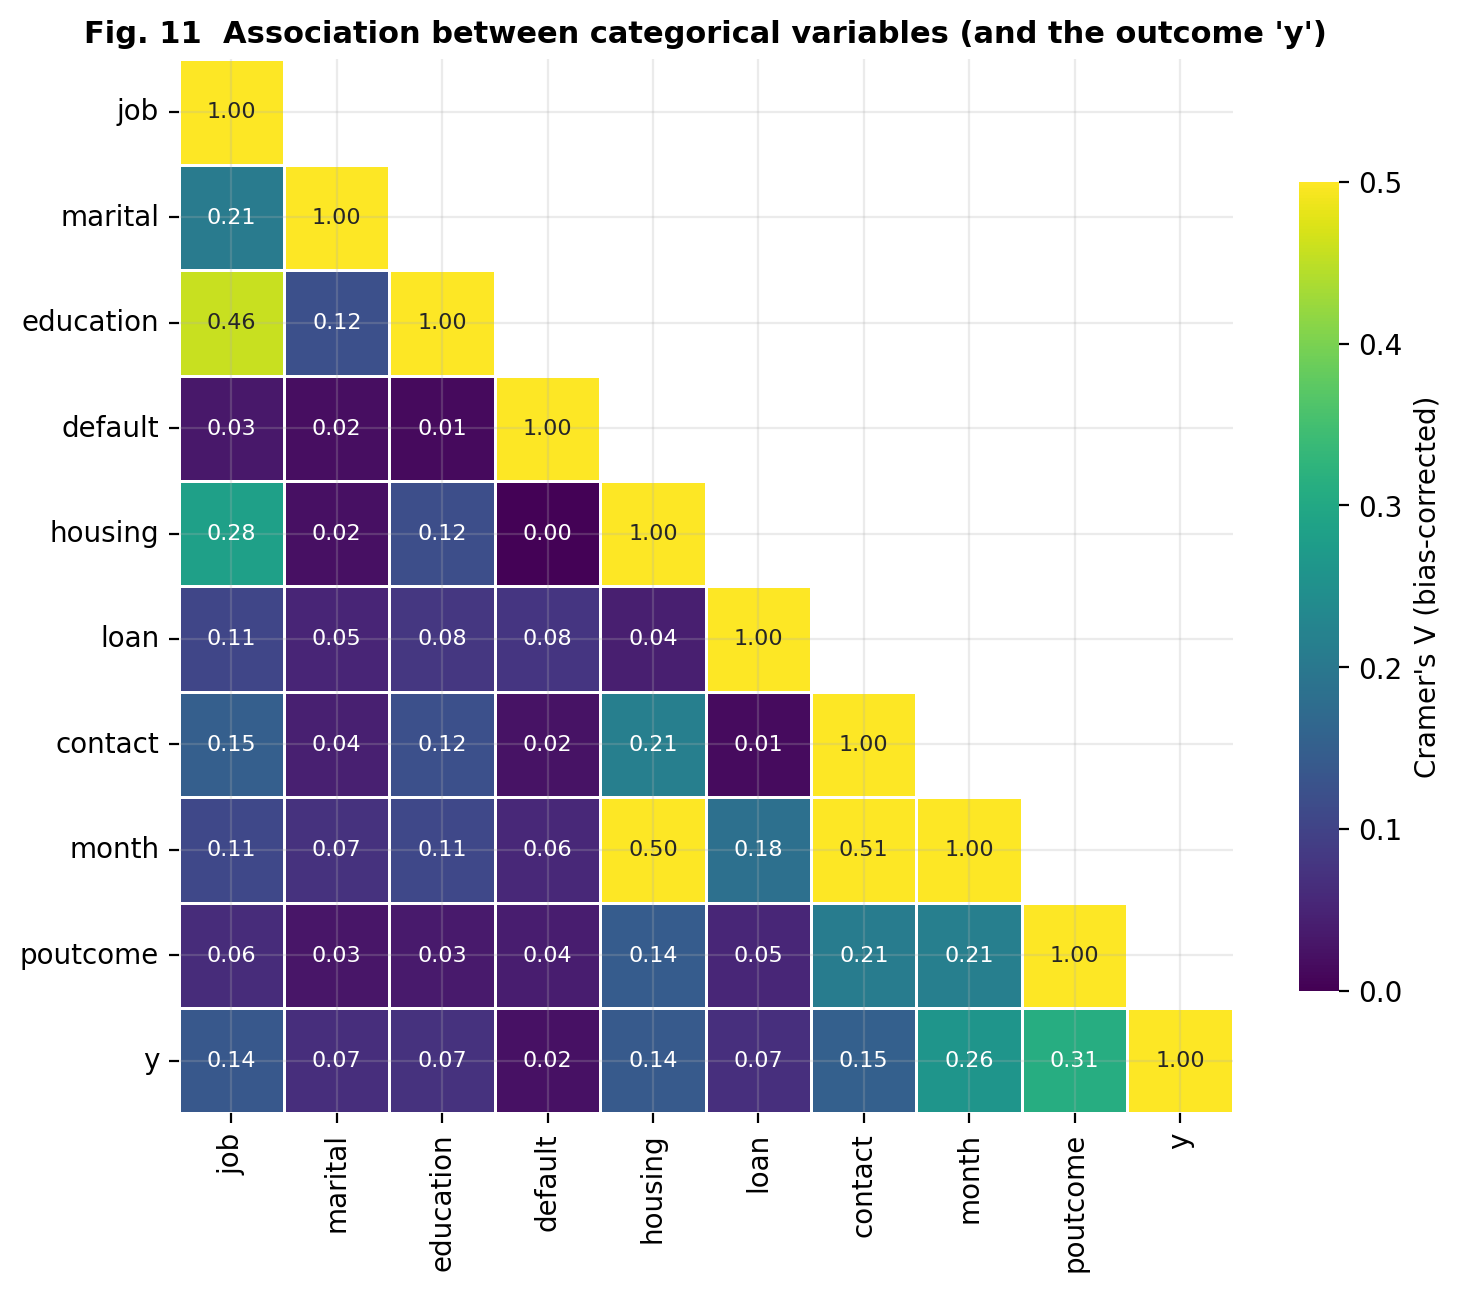

In [19]:
display(Image(str(FIG_DIR / 'fig11_cramers_heatmap.png'), width=900))

**Figure 11 - Association between categorical variables (Cramer's V)**

| | |
|---|---|
| **Question** | Which categorical variables are associated with the outcome and with each other? |
| **What it shows** | Lower-triangle heatmap of bias-corrected Cramer's V (0 = independent, 1 = perfectly associated). |
| **Why this chart** | Pearson/Spearman do not apply to nominal variables; Cramer's V (from chi-square) puts all pairs on one 0-1 scale. |
| **Variables** | job, marital, education, default, housing, loan, contact, month, poutcome, y. |
| **Finding** | Strongest links to y: poutcome 0.31, month 0.26, contact 0.15, housing 0.14, job 0.14; default only 0.02. Among predictors: month-contact 0.51, month-housing 0.50, job-education 0.46. |
| **Interpretation** | Previous campaign outcome and timing are the most informative categorical signals, while having credit in default carries almost no information. The large month-contact and month-housing values show that the client mix and the contact channel changed over the campaign, so marginal differences (Fig. 5) partly reflect timing. |
| **Caveats** | Cramer's V is symmetric and says nothing about direction; every chi-square test here is 'significant' because n is large, so effect size (V) matters more than p. |

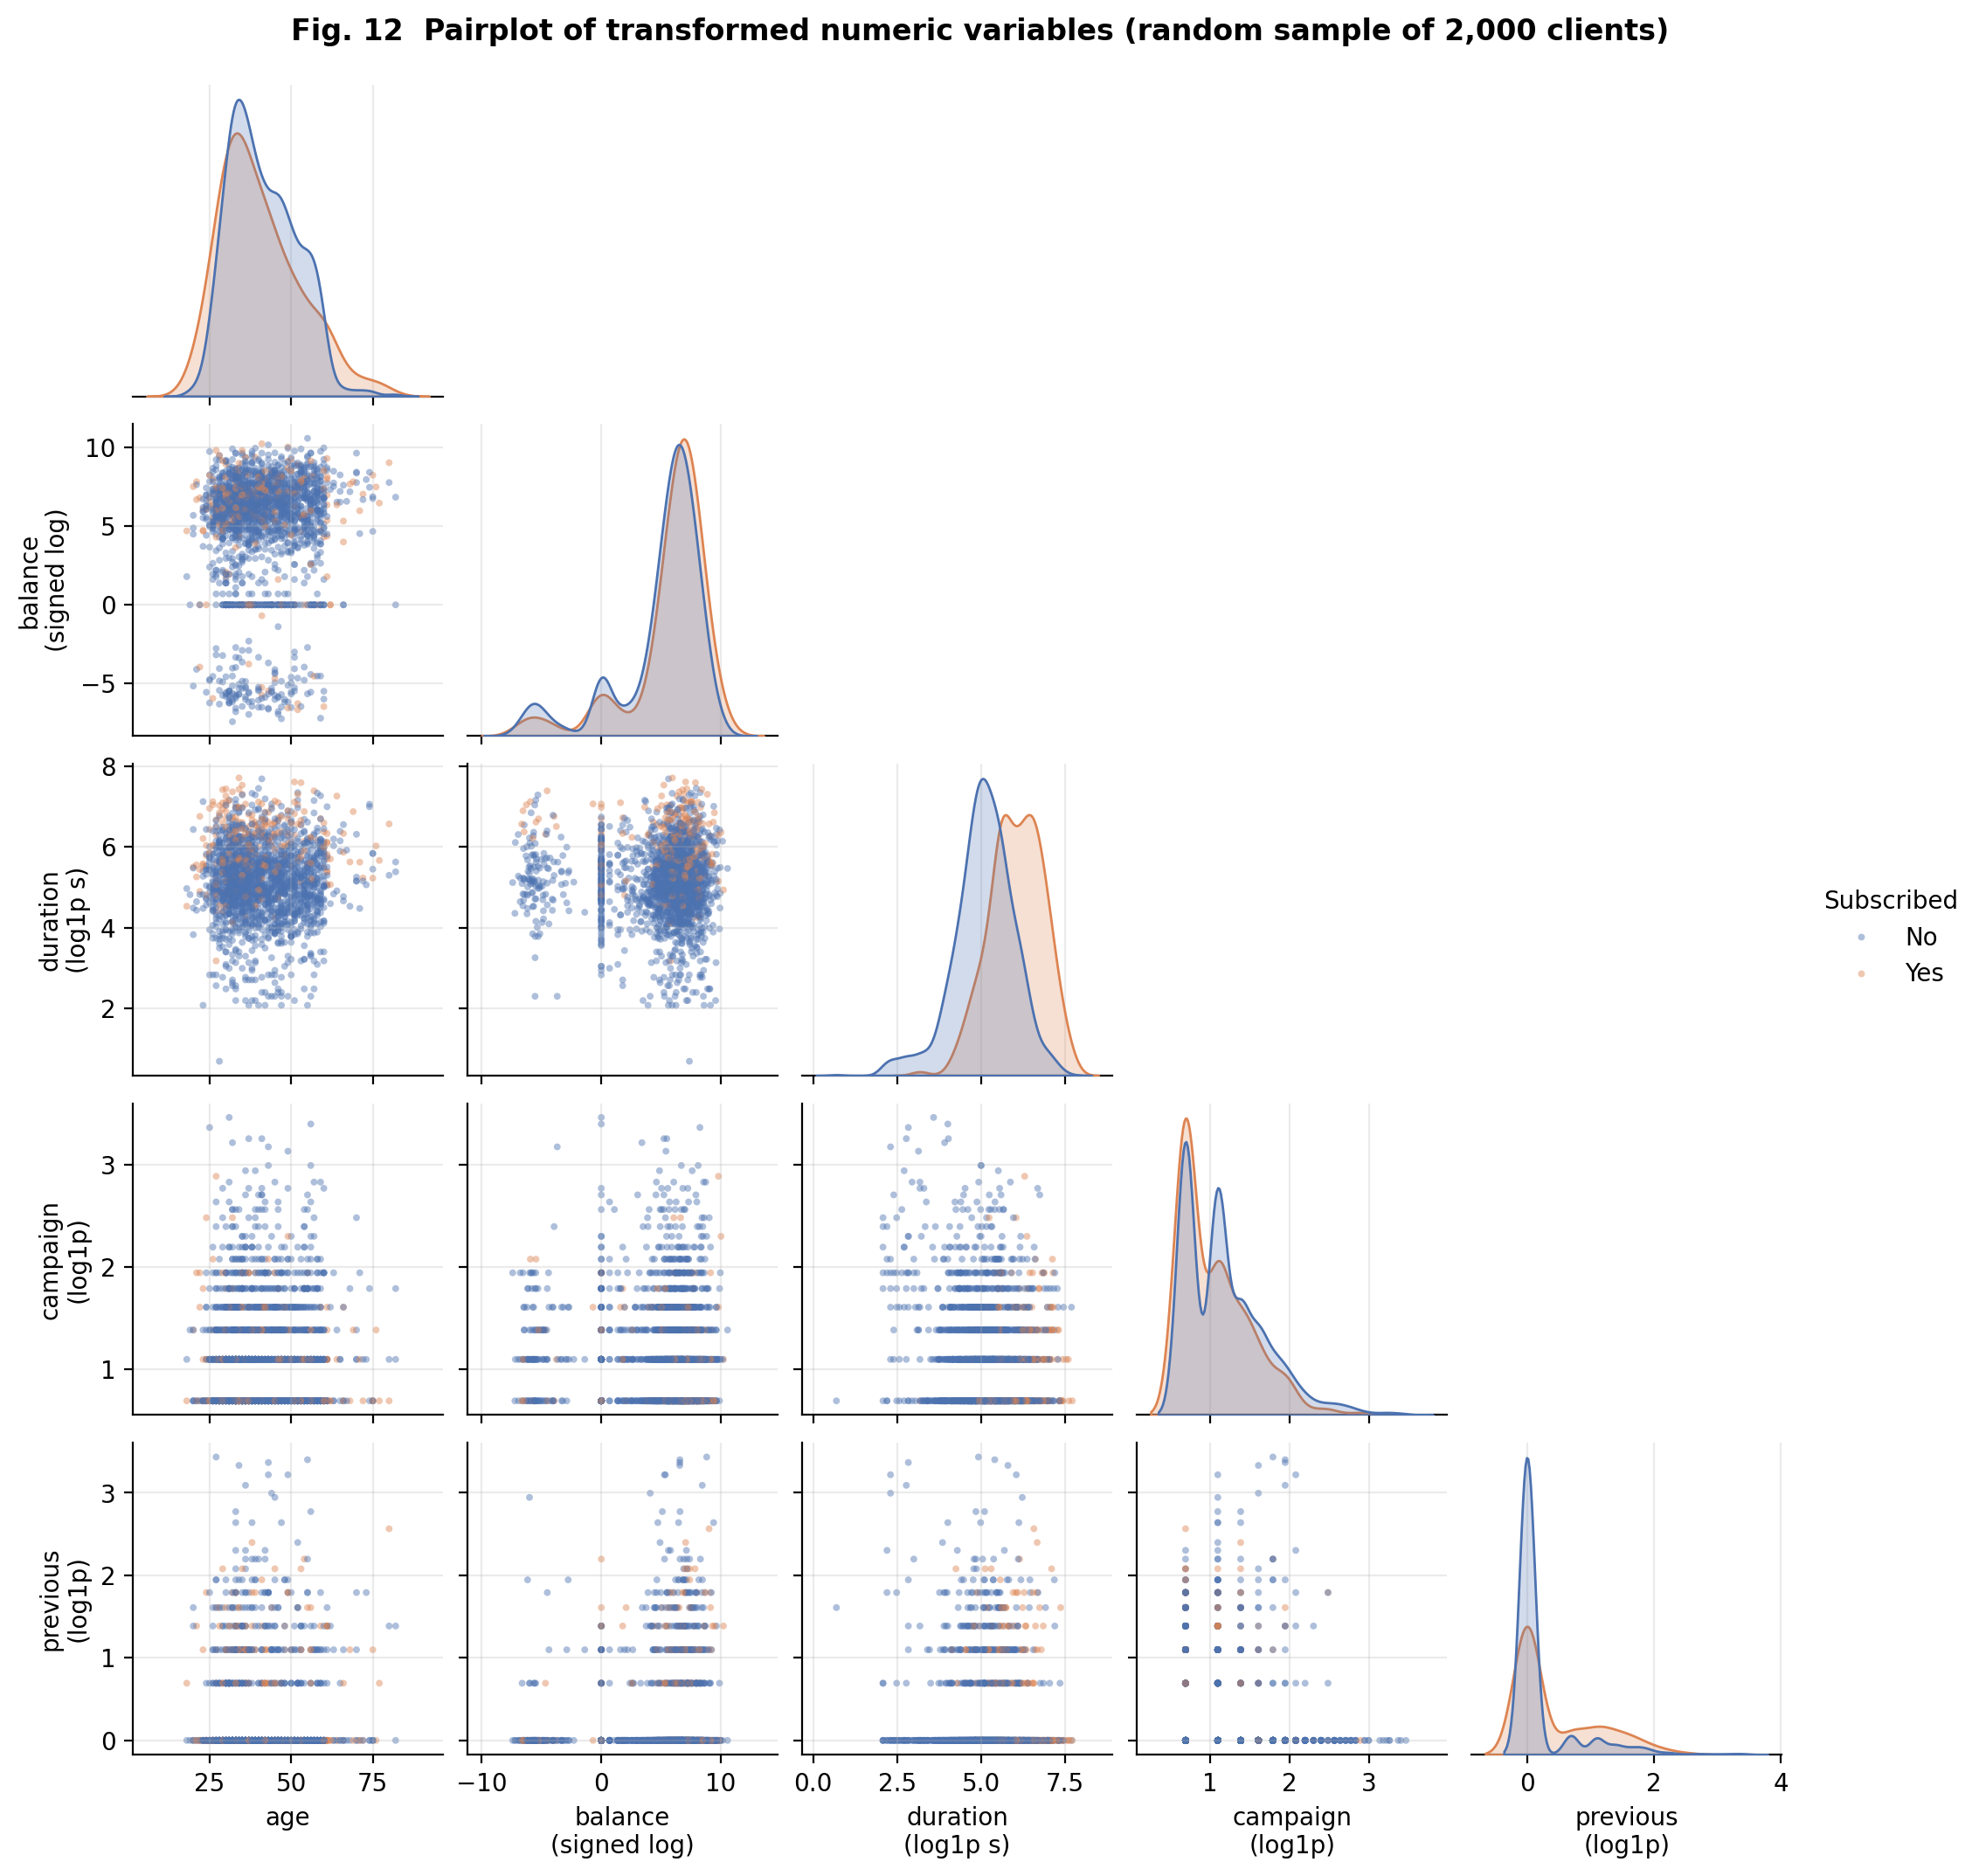

In [20]:
display(Image(str(FIG_DIR / 'fig12_pairplot.png'), width=900))

**Figure 12 - Pairplot of transformed numeric variables**

| | |
|---|---|
| **Question** | Do pairs of numeric variables show joint structure, clusters or separation by outcome? |
| **What it shows** | Scatter matrix (lower triangle) and class-wise KDEs (diagonal) of 2,000 random clients on log-type scales. |
| **Why this chart** | A pairplot gives a one-glance view of all bivariate relationships and class overlap; a sample keeps it legible. |
| **Variables** | age, balance (signed log), duration (log1p), campaign (log1p), previous (log1p), coloured by y. |
| **Finding** | balance on the signed-log scale is clearly multi-modal: a cluster of overdrawn accounts, a spike at exactly zero (3,514 clients = 7.8%) and a main mass of positive balances. Subscribers (orange) are shifted towards longer durations, but no pair of predictors shows a strong linear relation and the classes overlap heavily everywhere else. |
| **Interpretation** | No two predictors are strongly entangled (consistent with Fig. 10), and no simple two-variable boundary separates subscribers, which anticipates the moderate predictive ceiling seen later. The multi-modality of balance is invisible in the raw histogram. |
| **Caveats** | Based on a random sample of 2,000 rows (seed 42); campaign/previous form discrete lattices; overplotting hides density in the centre. |

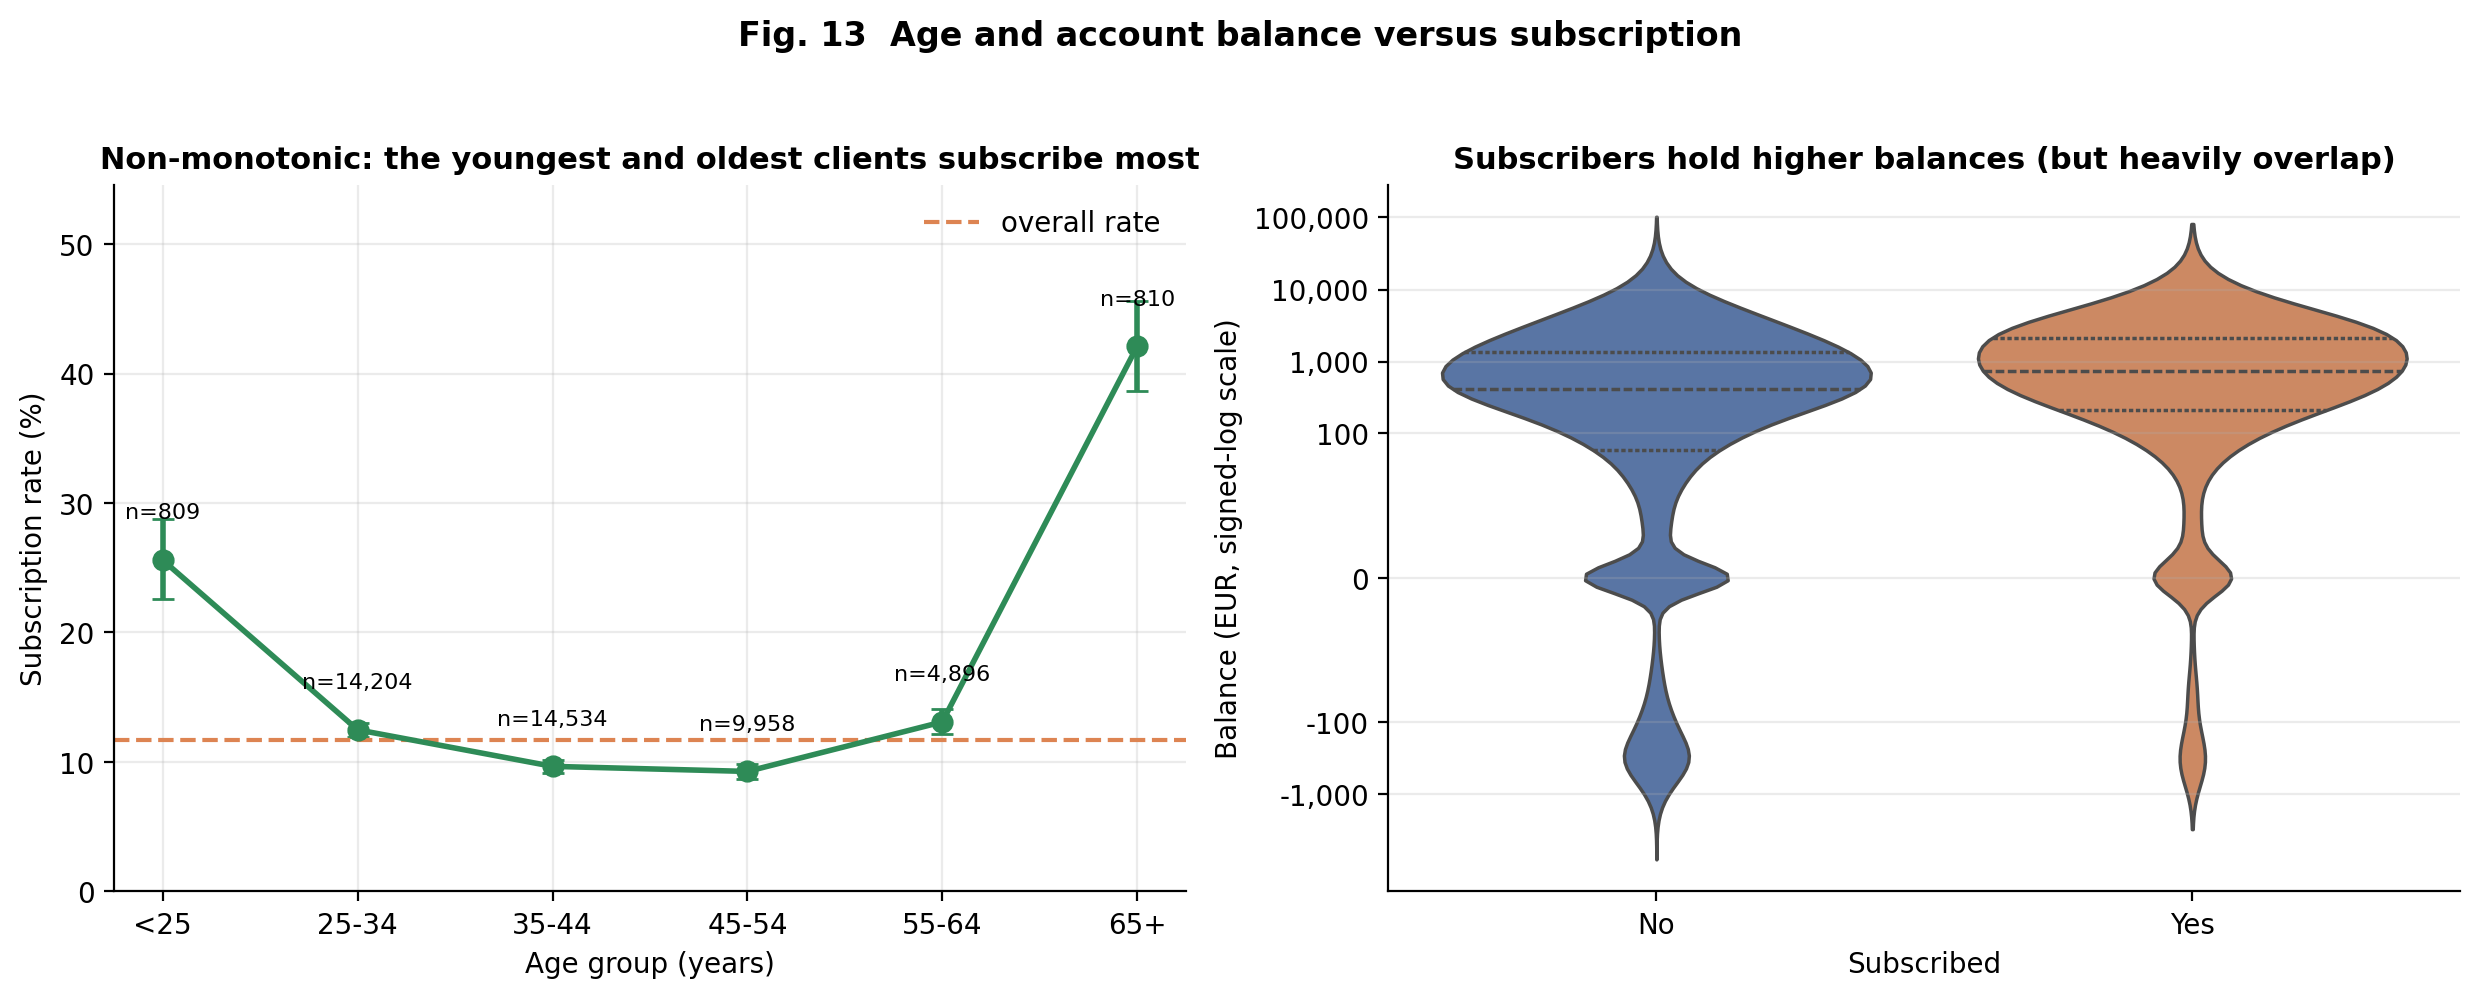

In [21]:
display(Image(str(FIG_DIR / 'fig13_age_and_balance.png'), width=900))

**Figure 13 - Age and balance versus subscription**

| | |
|---|---|
| **Question** | Does the relation between age or balance and subscription follow a simple monotonic trend? |
| **What it shows** | Left: subscription rate per age band with exact 95% CIs. Right: violin plots of signed-log balance by outcome with quartiles. |
| **Why this chart** | Binning age reveals shape that a single correlation coefficient hides; violins show full distributions and the overlap between classes. |
| **Variables** | age (grouped), balance, y. |
| **Finding** | Rate by age: <25 25.6% (n = 809), 45-54 9.3%, 65+ 42.1% (n = 810); yet Spearman rho(age, y) = -0.01 and Mann-Whitney p = 0.063 (median age 38 vs 39). Balance median EUR 733 (subscribers) vs EUR 417; Mann-Whitney p < 0.001, Cliff's delta = 0.18. |
| **Interpretation** | Age matters, but not linearly: the youngest and oldest clients are far more receptive than mid-career clients, which monotone tests (correlation, Mann-Whitney) miss completely. Higher balance is associated with subscription, but the small effect size (delta = 0.18) and the heavy overlap in the violins mean balance alone is a weak discriminator. |
| **Caveats** | Groups <25 and 65+ are small (about 800 each) and overlap with students and retirees (Fig. 5), so age and occupation effects cannot be separated here. |

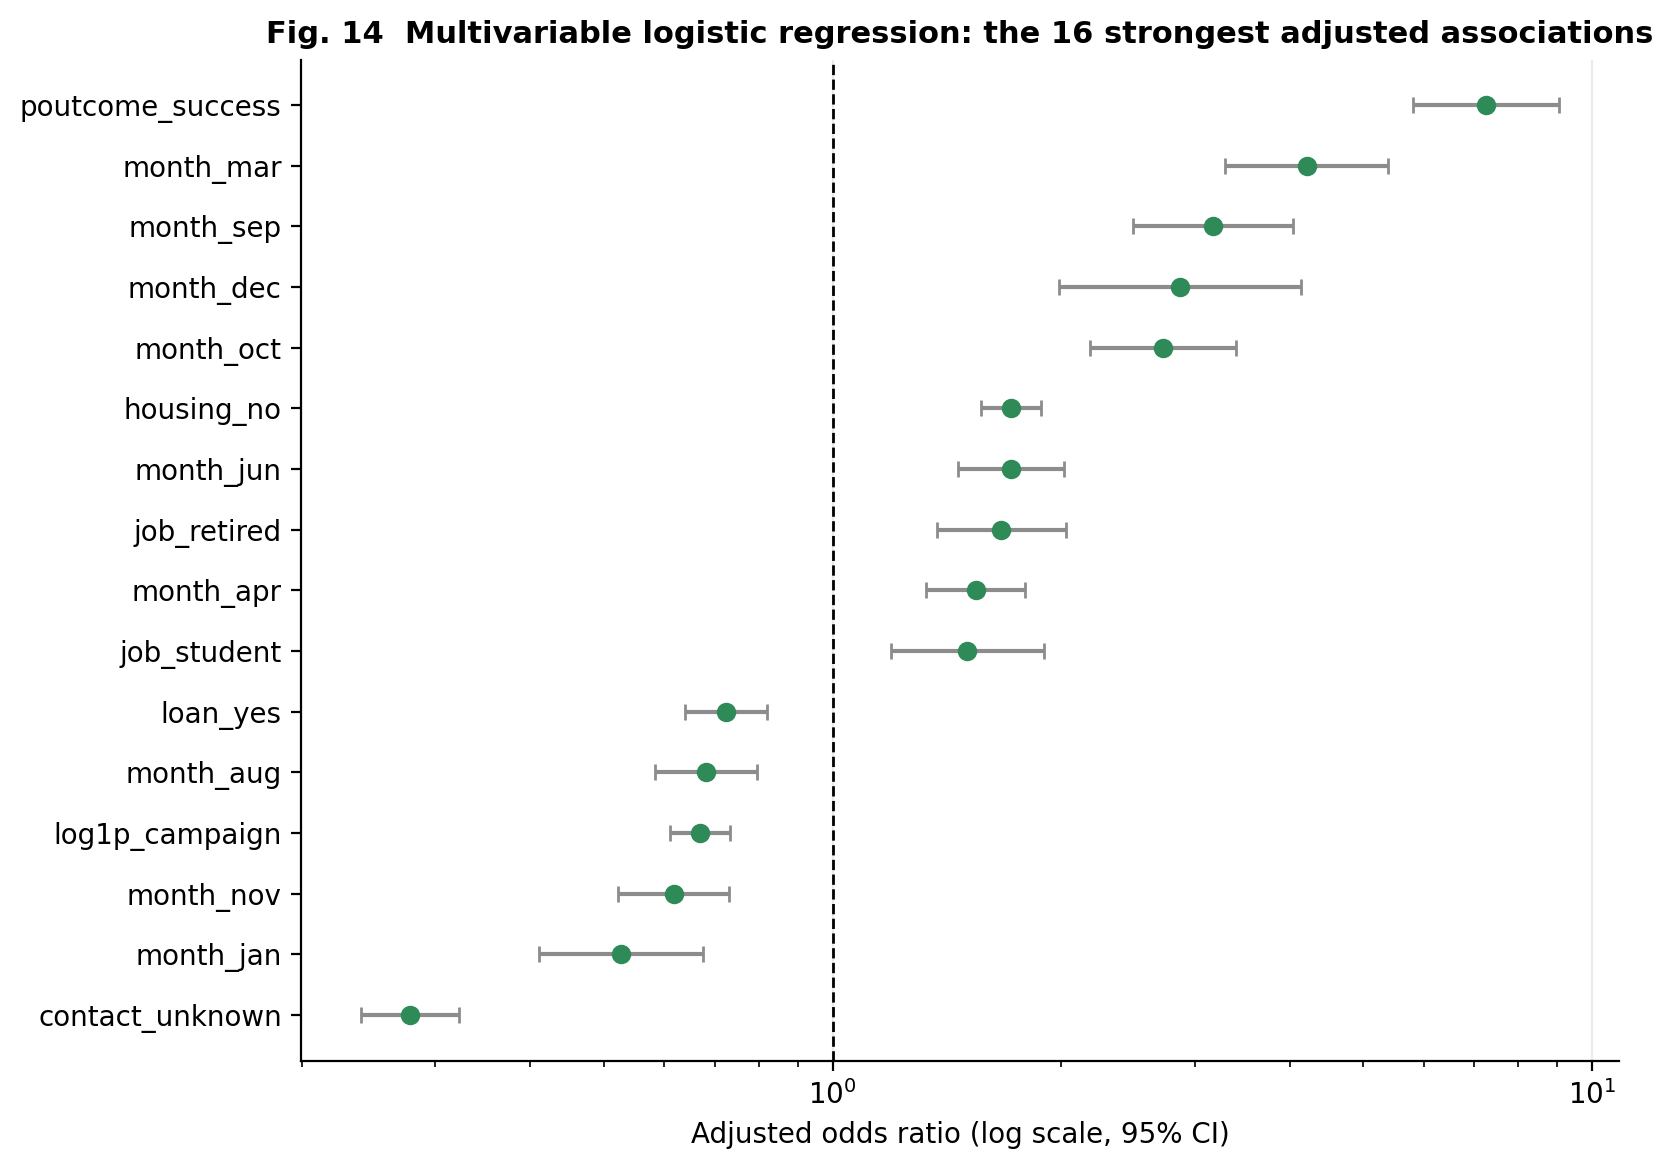

In [22]:
display(Image(str(FIG_DIR / 'fig14_odds_ratio_forest.png'), width=900))

**Figure 14 - Adjusted odds ratios from a multivariable logistic regression**

| | |
|---|---|
| **Question** | Which factors remain associated with subscription after adjusting for all the others? |
| **What it shows** | Odds ratios (log scale) with 95% CIs for the 16 largest effects; the dashed line at 1 means no association. |
| **Why this chart** | A forest plot is the standard way to compare adjusted effects on a common multiplicative scale with their uncertainty. |
| **Variables** | All pre-call predictors (n = 31,647 training clients; McFadden pseudo-R2 = 0.173). |
| **Finding** | poutcome = success: OR 7.24 (95% CI 5.80-9.04); March OR 4.21; contact unknown OR 0.28 (0.24-0.32); no housing loan OR 1.72; each unit of log(1 + campaign) OR 0.67. Before removing redundant predictors the maximum VIF was 1005 (5 variables above 10); afterwards 5.2. |
| **Interpretation** | After adjustment, a past success, particular months, a known contact channel and the absence of a housing loan are still associated with higher odds, and repeated contacting with lower odds. The model explains a modest share of variation (pseudo-R2 about 0.17), in line with the weak individual associations seen above. |
| **Caveats** | Odds ratios describe association, not causation. Month effects absorb campaign phase; the first fit with all history variables had unstable intervals because previous, pdays and previously_contacted are redundant, which is why only log(1 + previous) was retained. |

### Key statistical findings

1. **Only about one client in nine subscribes.** 5,289/45,211 = 11.70% (95% CI 11.40%-12.00%) (Fig. 1). *Implication:* Accuracy is uninformative (always answering 'no' gives 88.3%); the model is judged by ROC-AUC, PR-AUC and F1. *Caveat:* Rate is specific to this campaign's client selection.
2. **Missing data hide behind 'unknown' labels and a -1 sentinel, not NaN.** NaN cells = 0, but poutcome unknown 81.7%, contact unknown 28.8%, pdays = -1 for 81.7% (Fig. 4). *Implication:* 'unknown' is kept as a category and pdays is split into a flag plus a cleaned value; imputing the mode would erase real information. *Caveat:* contact = unknown is concentrated in May-June, so it mixes channel and timing.
3. **Balance, duration and the count variables are heavy-tailed; age is not normal.** balance skew 8.36, excess kurtosis 141; age Normal KS D = 0.096 (AIC +4,642 vs Lognormal) (Figs. 2, 3, 8). *Implication:* Signed-log and cap-then-log transforms are used; medians and rank-based tests replace means and t-tests. *Caveat:* No simple parametric family fits age well (best KS D = 0.061).
4. **Contact counts are over-dispersed, so Poisson is rejected in favour of Negative Binomial.** variance/mean = 5.4; AIC 220,368 (Poisson) vs 162,240 (NB); P(>=10 extra contacts) observed 2.65% vs Poisson 0.0016% (Fig. 7). *Implication:* Client contactability is heterogeneous, and rare, very persistent call sequences are far more common than a Poisson model predicts. *Caveat:* NB still fails a chi-square test in the tail; counts are shaped by bank stop-rules.
5. **Call duration is lognormal-like, not memoryless-exponential.** KS D: Lognormal 0.038 vs Exponential 0.106; AIC gap 3,768 (Fig. 9). *Implication:* Very short calls are rare and a typical call length exists, so time already spent on a call does carry information. *Caveat:* Only the last call per client is recorded.
6. **Conversion varies strongly by calendar month and is inversely related to call volume.** May: 13,766 calls at 6.7%; March: 477 calls at 52.0%; chi2(11) = 3062, V = 0.26 (Figs. 6, 11). *Implication:* One Bernoulli parameter does not describe all months; campaign timing/targeting must be modelled. *Caveat:* No year field; low-volume months were probably selectively targeted, so this is not causal.
7. **A previous successful campaign is the strongest single signal.** 64.7% vs 9.2% (unknown); adjusted OR 7.24 (95% CI 5.80-9.04) (Figs. 5, 14). *Implication:* Re-contacting previously converted clients is likely the most productive use of calls. *Caveat:* Only 3.3% of clients have a previous success.
8. **Age has a U-shaped, non-monotonic relation with subscription that correlation misses.** <25: 25.6%, 45-54: 9.3%, 65+: 42.1%; Spearman rho = -0.01 (Fig. 13). *Implication:* Age should enter models as a non-linear effect; segment-specific offers for students and retirees are plausible. *Caveat:* Extreme groups are small (~800) and overlap with job categories.
9. **Existing loan commitments go with lower subscription.** housing loan: 7.7% vs no housing loan 16.7%; adjusted OR (no housing) = 1.72 (Figs. 5, 14). *Implication:* Clients with fewer credit commitments are a more receptive segment. *Caveat:* Association only; housing loans are also tied to month (V = 0.50).
10. **The MLP has moderate, honest predictive power; call duration would be a leak.** test ROC-AUC 0.784 +/- 0.002 (5 seeds), PR-AUC 0.415; LR 0.759; GB 0.801; with duration 0.918; chronological 0.642 (Figs. 15-22). *Implication:* The model can rank prospects usefully (precision about 3.7x prevalence at the F1 threshold) but is not accurate enough to automate decisions. *Caveat:* Random-split score is optimistic under temporal shift.

## 7. Interact
Stage 7: a self-contained Plotly explorer (dropdowns, hover, zoom). Open `outputs/interactive/explorer.html` in a browser.

In [23]:
from src.interactive import build_explorer
print("Open in your browser:", build_explorer(cdf))

Open in your browser: /home/claude/bank-marketing-eda-dl/outputs/interactive/explorer.html


## 8. Deep learning model (MLP) - training, evaluation and visualization
Set `RETRAIN = True` to re-run the whole experiment (about 10-15 min on one CPU core; resumable). With `False` the notebook loads the saved results of the full run (`outputs/results/`), which come from executing `python -m src.train`.

In [24]:
RETRAIN = False
if RETRAIN:
    from src.train import run_experiments
    run_experiments(quick=False)
MR = json.loads((RES_DIR / "model_results.json").read_text())
assert not MR["quick_smoke_test"]
print("best config:", MR["best_config"], "| parameters:", MR["n_params"], "| inputs:", MR["n_inputs"])
print("\n".join(MR["architecture_summary"]))

best config: {'units': [32], 'dropout': 0.2, 'lr': 0.001, 'class_weight': None} | parameters: 1697 | inputs: 51
Model: "bank_mlp"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 51)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_subscribe (Dense)             │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 5,093 (1

In [25]:
rows = {"MLP (primary seed 42)": MR["primary"]["test"]}
rows.update({k: v["test"] for k, v in MR["baselines"].items()})
res = pd.DataFrame(rows).T[["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy", "balanced_accuracy", "mcc"]].round(3)
display(res)
print("MLP over 5 seeds (mean, sd):", {k: [round(x, 4) for x in v] for k, v in MR["test_mean_std"].items() if k in ("roc_auc", "pr_auc", "f1")})
display(pd.read_csv(RES_DIR / "hparam_search.csv").round(4))
display(pd.read_csv(RES_DIR / "robustness.csv").round(3))

,roc_auc,pr_auc,f1,precision,recall,accuracy,balanced_accuracy,mcc
MLP (primary seed 42),0.784,0.413,0.457,0.435,0.482,0.866,0.699,0.381
Majority class,0.500,0.117,0.209,0.117,1.000,0.117,0.500,0.000
Logistic regression,0.759,0.384,0.431,0.464,0.402,0.876,0.670,0.363
Gradient boosting (reference),0.801,0.439,0.476,0.426,0.538,0.861,0.721,0.400


MLP over 5 seeds (mean, sd): {'roc_auc': [0.7843, 0.0019], 'pr_auc': [0.415, 0.0043], 'f1': [0.4605, 0.0035]}


,config_id,units,dropout,lr,class_weight,epochs_run,best_epoch,val_roc_auc,val_pr_auc,seconds
0,2,"(32,)",0.2,0.0010,none,40,38,0.7979,0.4555,13.6
1,0,"(128, 64, 32)",0.4,0.0010,none,40,36,0.8027,0.4541,27.0
2,6,"(32,)",0.4,0.0010,none,40,40,0.7926,0.4532,13.8
3,11,"(128, 64, 32)",0.4,0.0010,balanced,36,30,0.8004,0.4520,23.4
4,9,"(64, 32)",0.2,0.0010,balanced,30,24,0.7984,0.4517,14.6
5,5,"(128, 64, 32)",0.2,0.0003,balanced,40,40,0.7975,0.4507,25.8
6,3,"(64, 32)",0.2,0.0010,none,40,40,0.7981,0.4502,15.6
7,7,"(128, 64, 32)",0.4,0.0003,none,40,39,0.7946,0.4447,25.7
8,1,"(32,)",0.2,0.0003,balanced,40,40,0.7942,0.4398,13.8
9,8,"(32,)",0.2,0.0003,none,40,40,0.7888,0.4368,12.9


,setting,model,test_roc_auc,test_pr_auc,test_f1,test_prevalence
0,"Pre-call features\n(primary, stratified)",MLP,0.784,0.415,0.461,0.117
1,"Pre-call features\n(primary, stratified)",Logistic regression,0.759,0.384,0.431,0.117
2,"Pre-call features\n(primary, stratified)",Gradient boosting,0.801,0.439,0.476,0.117
3,+ call duration\n(not known pre-call),MLP,0.918,0.606,0.594,0.117
4,+ call duration\n(not known pre-call),Logistic regression,0.901,0.556,0.559,0.117
5,+ call duration\n(not known pre-call),Gradient boosting,0.930,0.621,0.621,0.117
6,"Pre-call features,\nchronological split",MLP,0.642,0.506,0.523,0.393
7,"Pre-call features,\nchronological split",Logistic regression,0.647,0.506,0.401,0.393
8,"Pre-call features,\nchronological split",Gradient boosting,0.583,0.462,0.554,0.393


In [26]:
from src.evaluate import make_model_figures
mfigs, m_test = make_model_figures()
print({k: v.name for k, v in mfigs.items()})

{15: 'fig15_hparam_search.png', 16: 'fig16_loss_curves.png', 17: 'fig17_accuracy_auc_curves.png', 18: 'fig18_confusion_matrix.png', 19: 'fig19_roc_pr_curves.png', 20: 'fig20_permutation_importance.png', 21: 'fig21_threshold_tradeoff.png', 22: 'fig22_robustness.png'}


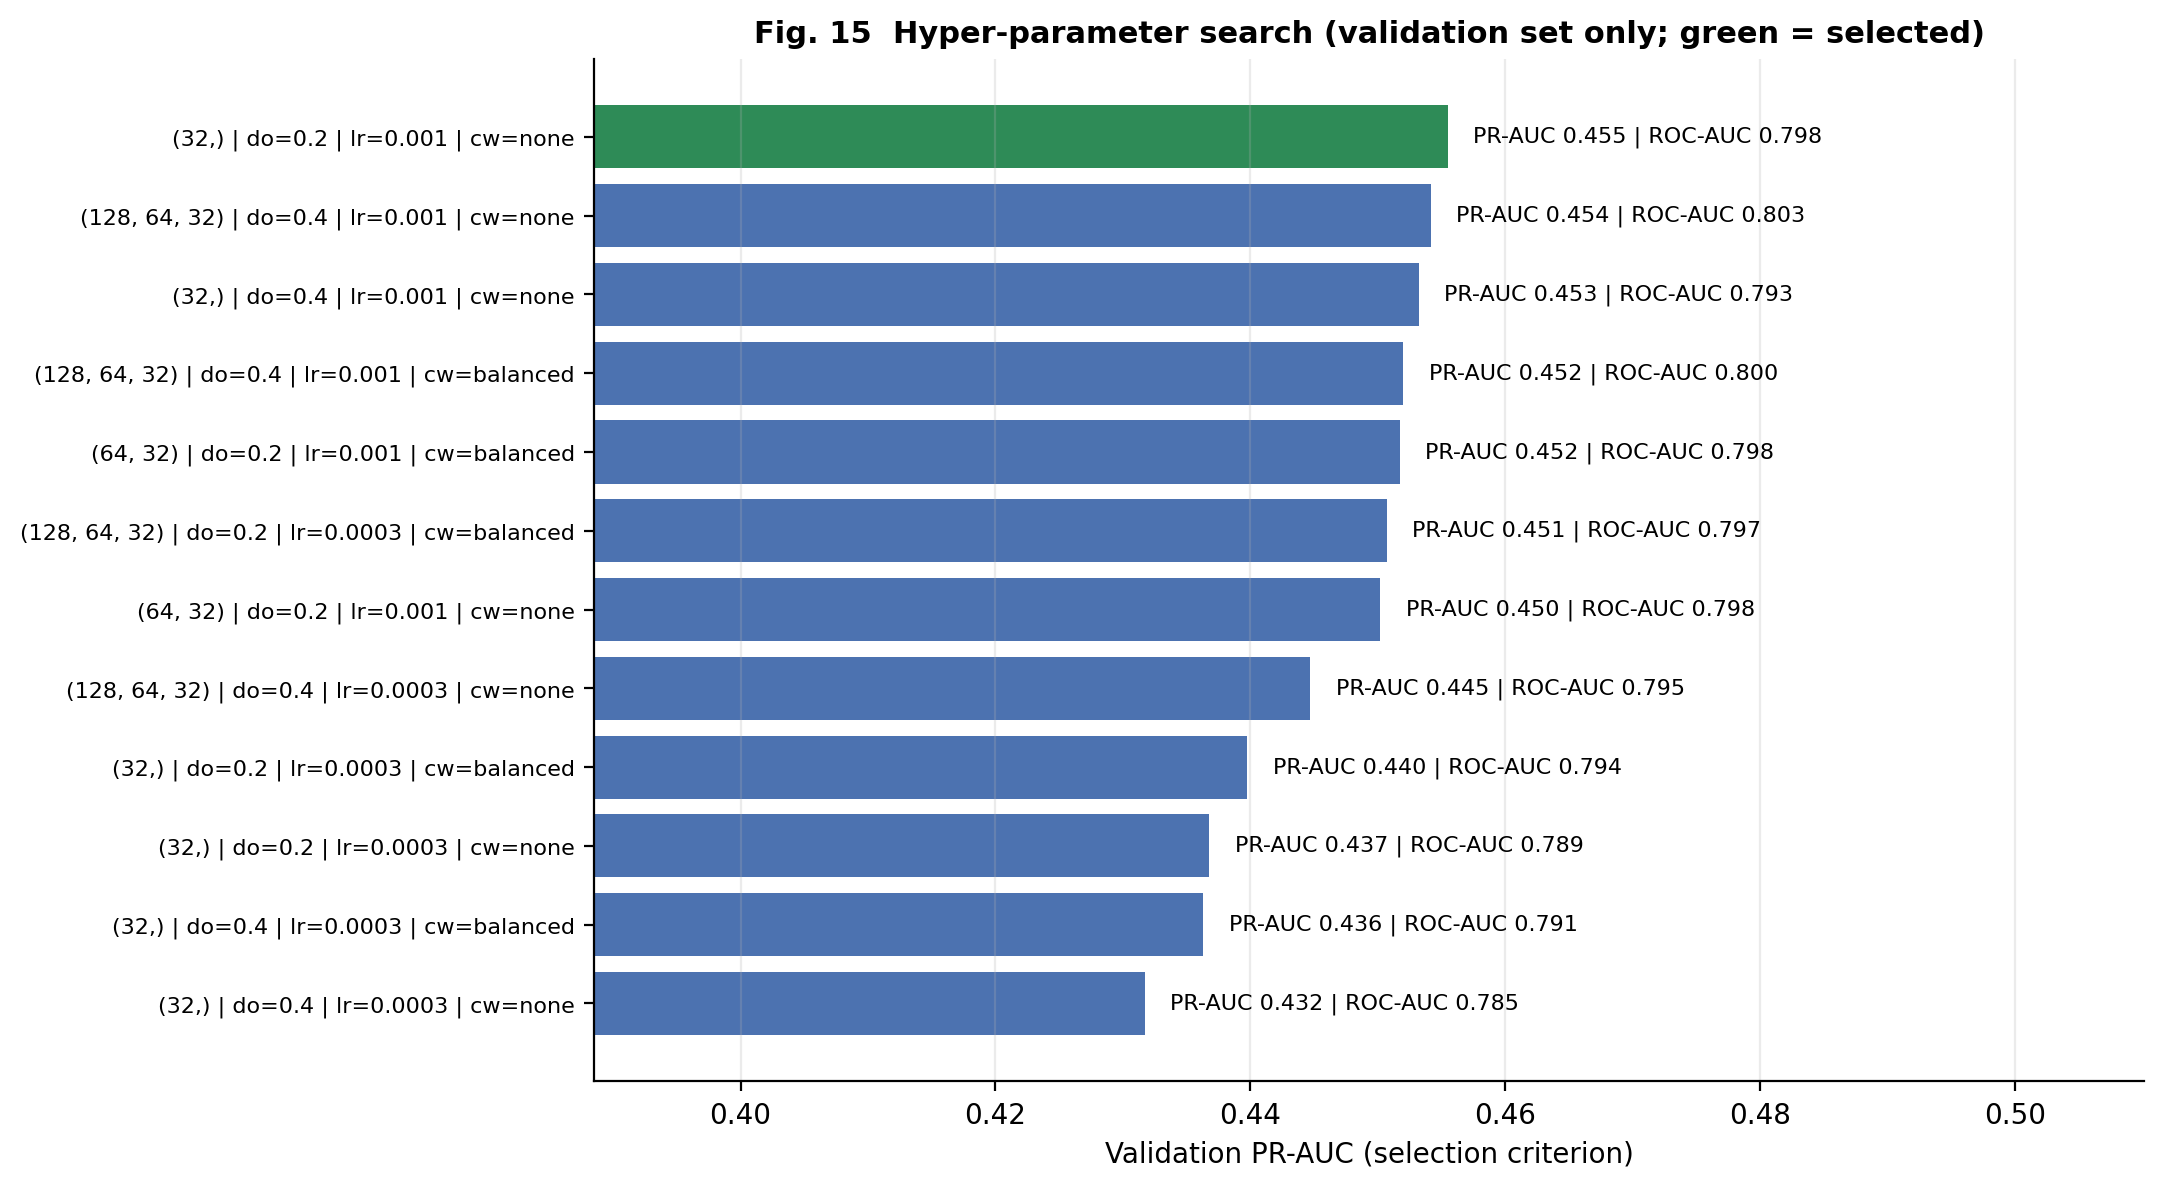

In [27]:
display(Image(str(FIG_DIR / 'fig15_hparam_search.png'), width=850))

**Figure 15 - Hyper-parameter search**

| | |
|---|---|
| **Question** | Which MLP configuration generalises best to unseen (validation) data? |
| **What it shows** | Validation PR-AUC of 12 randomly sampled configurations (units, dropout, learning rate, class weighting); green = selected. |
| **Why this chart** | A sorted bar chart shows both the spread between configurations and how much tuning actually matters. |
| **Variables** | Hidden units, dropout, learning rate, class weights. |
| **Finding** | Validation PR-AUC ranged from 0.432 to 0.455 (ROC-AUC 0.785-0.803). Selected: units (32,), dropout 0.2, lr 0.001, class weight none. |
| **Interpretation** | The spread between best and worst configuration is only 0.024 PR-AUC, so tuning matters little here; the simplest architecture won, and the three-layer networks did not outperform it. Selection used the validation set only. |
| **Caveats** | Only 12 of 24 grid points were sampled, each with one seed, so small differences are not statistically meaningful. The test set was never used for selection. |

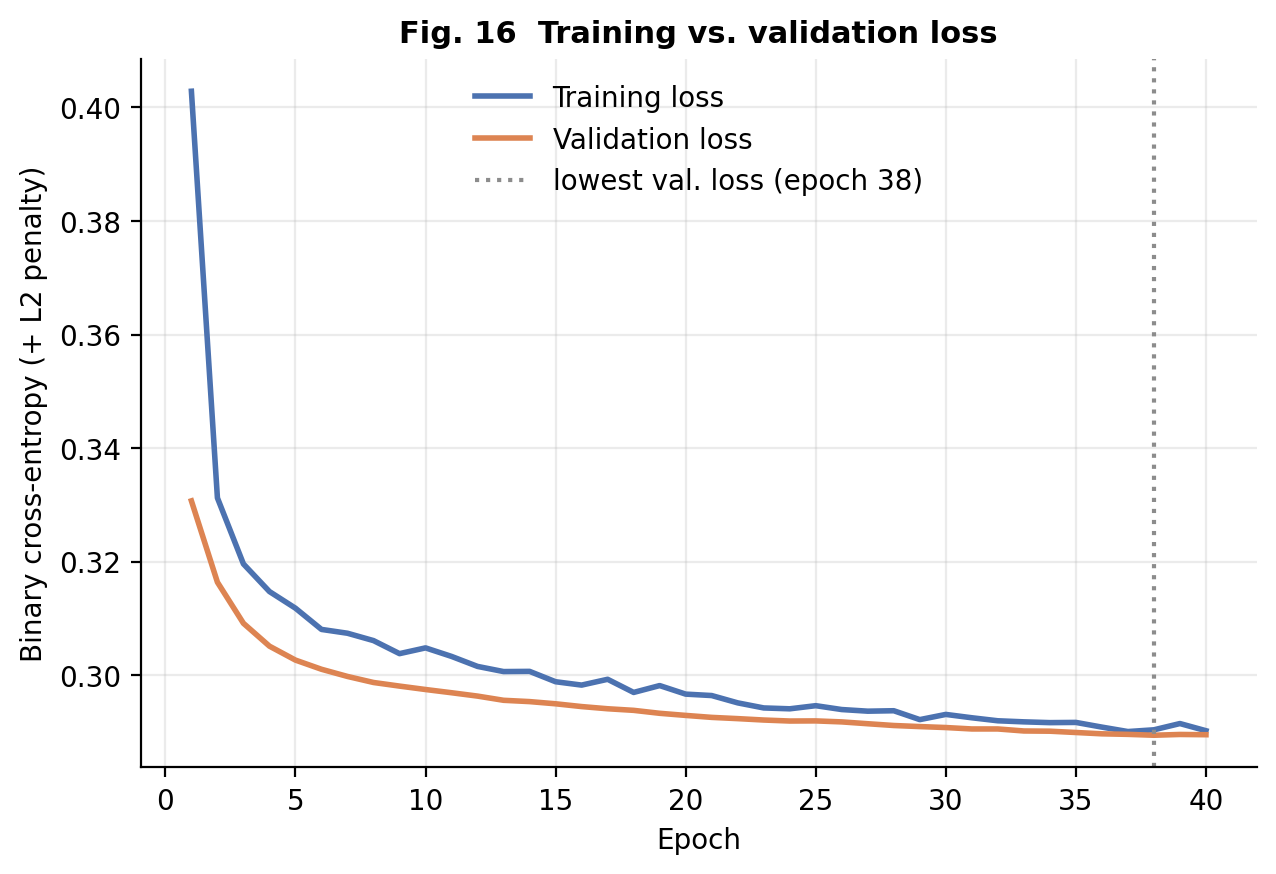

In [28]:
display(Image(str(FIG_DIR / 'fig16_loss_curves.png'), width=850))

**Figure 16 - Training versus validation loss**

| | |
|---|---|
| **Question** | Is the network underfitting or overfitting? |
| **What it shows** | Binary cross-entropy per epoch on the training and validation sets for the primary model. |
| **Why this chart** | The gap between the two loss curves is the standard diagnostic of generalisation. |
| **Variables** | Epoch, loss. |
| **Finding** | The run used all 40 allowed epochs (early stopping with patience 6 never triggered); lowest validation loss 0.289 at epoch 38 and best validation ROC-AUC at epoch 38. Final training loss 0.290 vs validation loss 0.290; first-epoch training loss 0.403. |
| **Interpretation** | Both curves fall together and end almost on top of each other, so there is no sign of overfitting (training loss is slightly higher because dropout is active during training). The curves are nearly flat by the end, so extra epochs would add very little: performance is limited by the information in the 16 pre-call features and the small network, not by memorisation. |
| **Caveats** | Training reached the 40-epoch cap while still improving marginally in the third decimal, so a longer run might give a tiny gain. Loss includes the L2 penalty. |

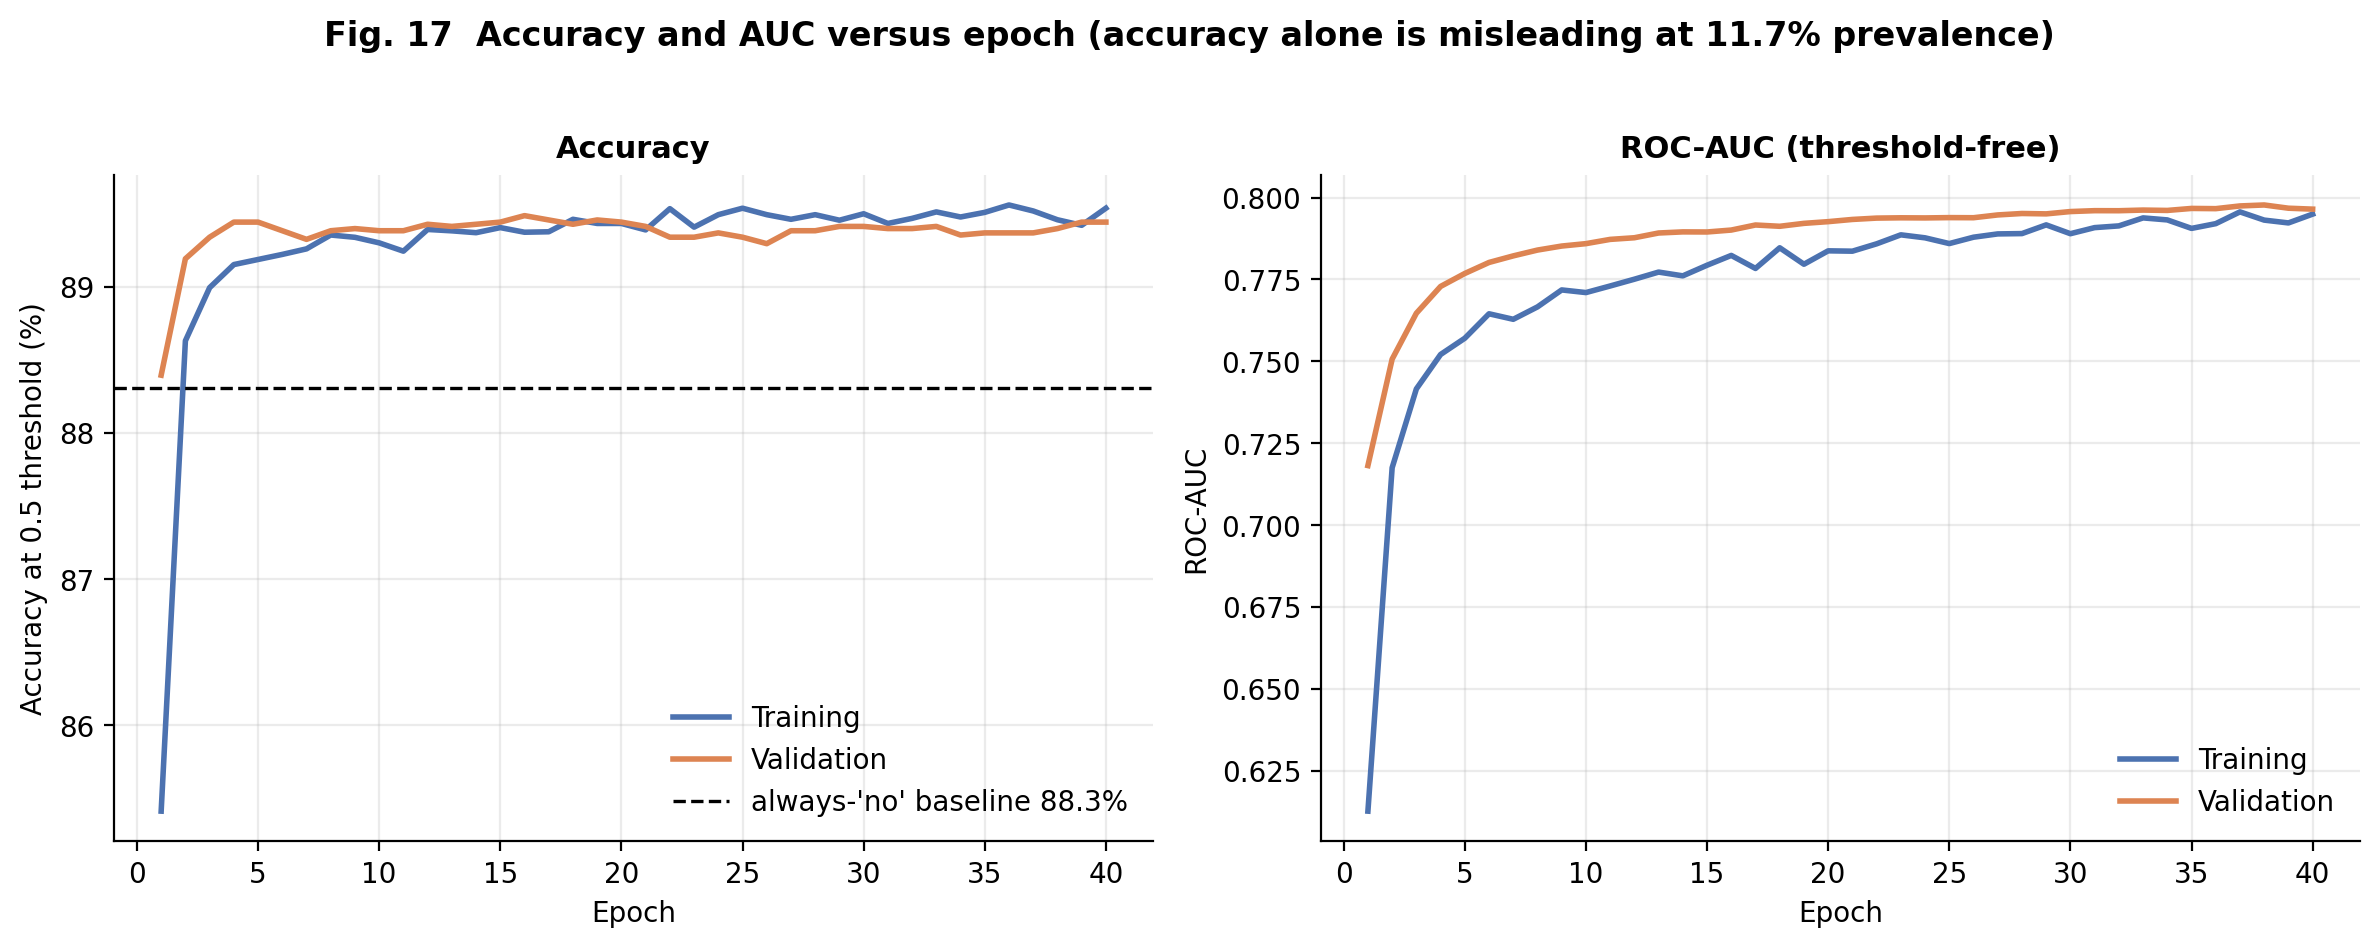

In [29]:
display(Image(str(FIG_DIR / 'fig17_accuracy_auc_curves.png'), width=850))

**Figure 17 - Accuracy and AUC versus epoch**

| | |
|---|---|
| **Question** | How do accuracy and ranking quality evolve during training? |
| **What it shows** | Left: accuracy at a 0.5 threshold against the always-'no' baseline. Right: ROC-AUC per epoch (training and validation). |
| **Why this chart** | The assignment requires accuracy-versus-epoch; the AUC panel and baseline line prevent the misleading impression that high accuracy means skill when 88% of clients decline. |
| **Variables** | Epoch, accuracy, ROC-AUC. |
| **Finding** | Validation accuracy at the 0.5 threshold ends at 89.4%, only about 1.1 points above the always-'no' baseline of 88.3%; validation AUC peaks at 0.798 (epoch 38) and training AUC at 0.796. |
| **Interpretation** | Accuracy barely moves because the class prior dominates it; AUC shows the real learning (ranking ability) and the two AUC curves track each other closely, confirming the absence of overfitting seen in Fig. 16. |
| **Caveats** | Accuracy depends on the 0.5 threshold, which is not the threshold used for final reporting (Fig. 21). |

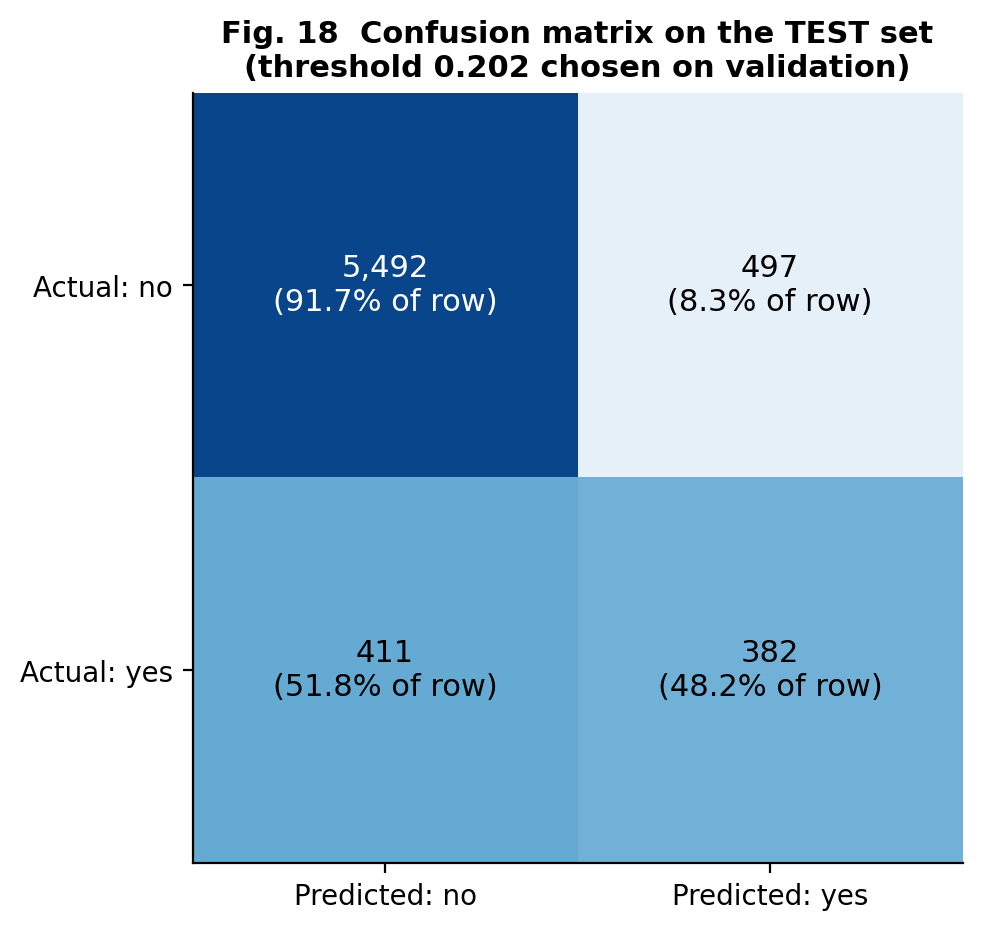

In [30]:
display(Image(str(FIG_DIR / 'fig18_confusion_matrix.png'), width=850))

**Figure 18 - Confusion matrix (test set)**

| | |
|---|---|
| **Question** | What kinds of mistakes does the final model make at the validation-chosen threshold? |
| **What it shows** | Counts and row-percentages of true/false positives and negatives on the untouched test set. |
| **Why this chart** | A confusion matrix converts a score into concrete outcomes (missed subscribers vs wasted calls). |
| **Variables** | Predicted vs actual y; threshold 0.202 (maximises F1 on validation). |
| **Finding** | TN 5,492, FP 497, FN 411, TP 382. Recall 48.2%, precision 43.5%, F1 0.457, accuracy 86.6%, balanced accuracy 69.9%, MCC 0.381. |
| **Interpretation** | At this operating point the model finds 48% of actual subscribers but only 43% of the clients it flags actually subscribe (prevalence 11.7%), i.e. roughly 3.7x better than random targeting. The two error types are of similar size (497 wasted calls vs 411 missed subscribers), and the model still misses about half of the subscribers, so it is a prioritisation aid rather than a reliable classifier. |
| **Caveats** | The threshold optimises F1, which weights precision and recall equally; a real campaign would choose it from call cost and expected revenue. |

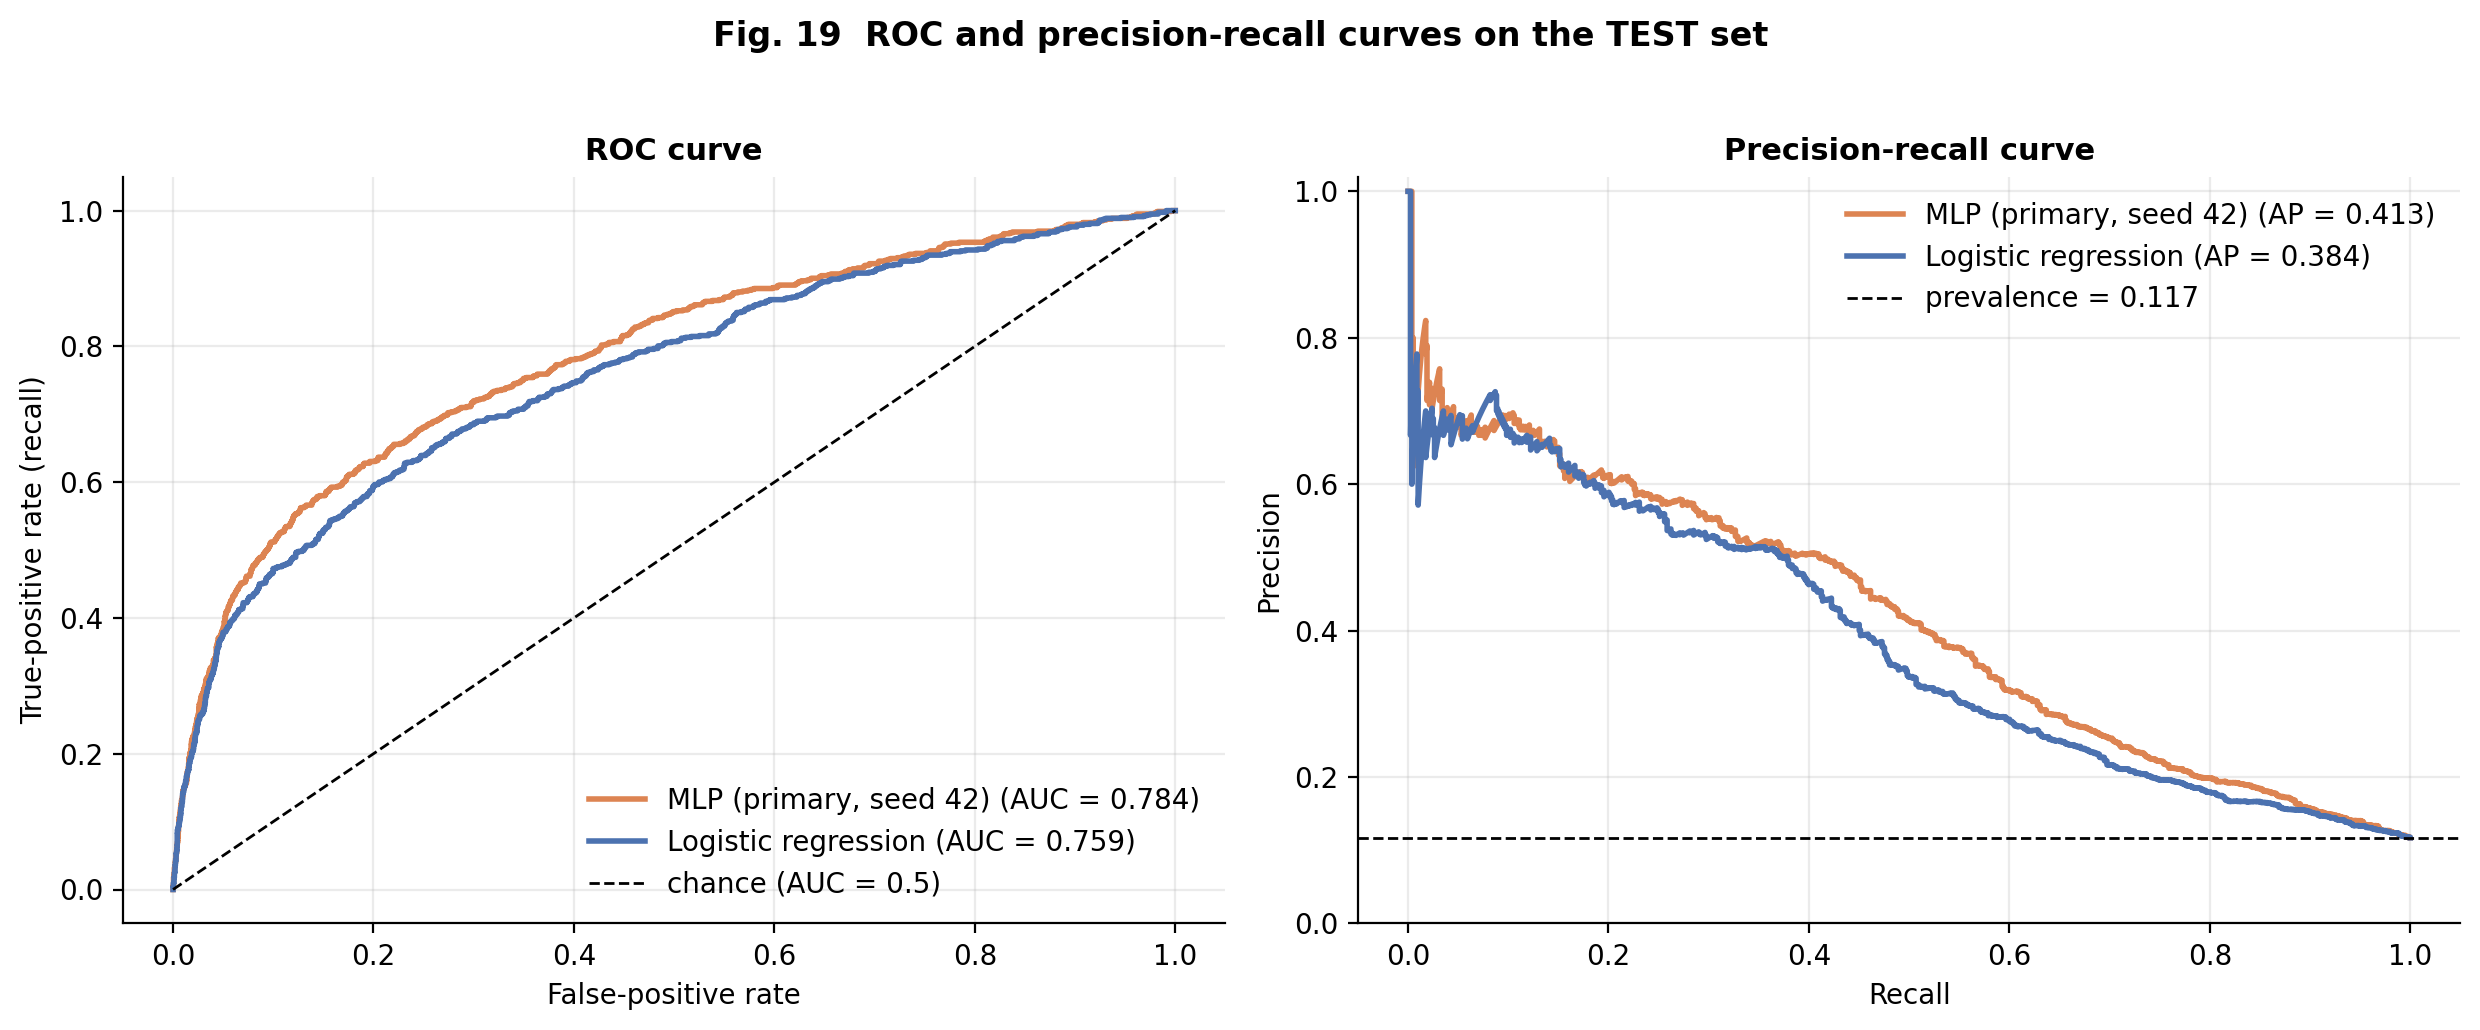

In [31]:
display(Image(str(FIG_DIR / 'fig19_roc_pr_curves.png'), width=850))

**Figure 19 - ROC and precision-recall curves (test set)**

| | |
|---|---|
| **Question** | How well does the model rank subscribers above non-subscribers across all thresholds? |
| **What it shows** | ROC curve (TPR vs FPR) and precision-recall curve for the MLP and the logistic-regression baseline. |
| **Why this chart** | ROC-AUC is threshold-free; the PR curve is more informative with 11.7% prevalence (Saito & Rehmsmeier, 2015). |
| **Variables** | Predicted probability, y. |
| **Finding** | Primary MLP: ROC-AUC 0.784, PR-AUC (average precision) 0.413 versus prevalence 0.117. Over 5 seeds ROC-AUC = 0.784 +/- 0.002. Baselines (test ROC-AUC): logistic regression 0.759, gradient boosting 0.801, majority class 0.500. |
| **Interpretation** | The MLP has real discriminative power (a random client pair is ranked correctly 78.4% of the time) and PR-AUC is about 3.5x the prevalence. The MLP beats the logistic-regression baseline by 0.025 AUC, which suggests it captures some non-linear structure, but the gradient-boosting reference is better still (+0.016), consistent with published evidence that tree ensembles are hard to beat on tabular data (Grinsztajn et al., 2022). |
| **Caveats** | Single test set of 6,782 clients: differences of about 0.01 AUC between models are within the seed-to-seed and sampling noise. |

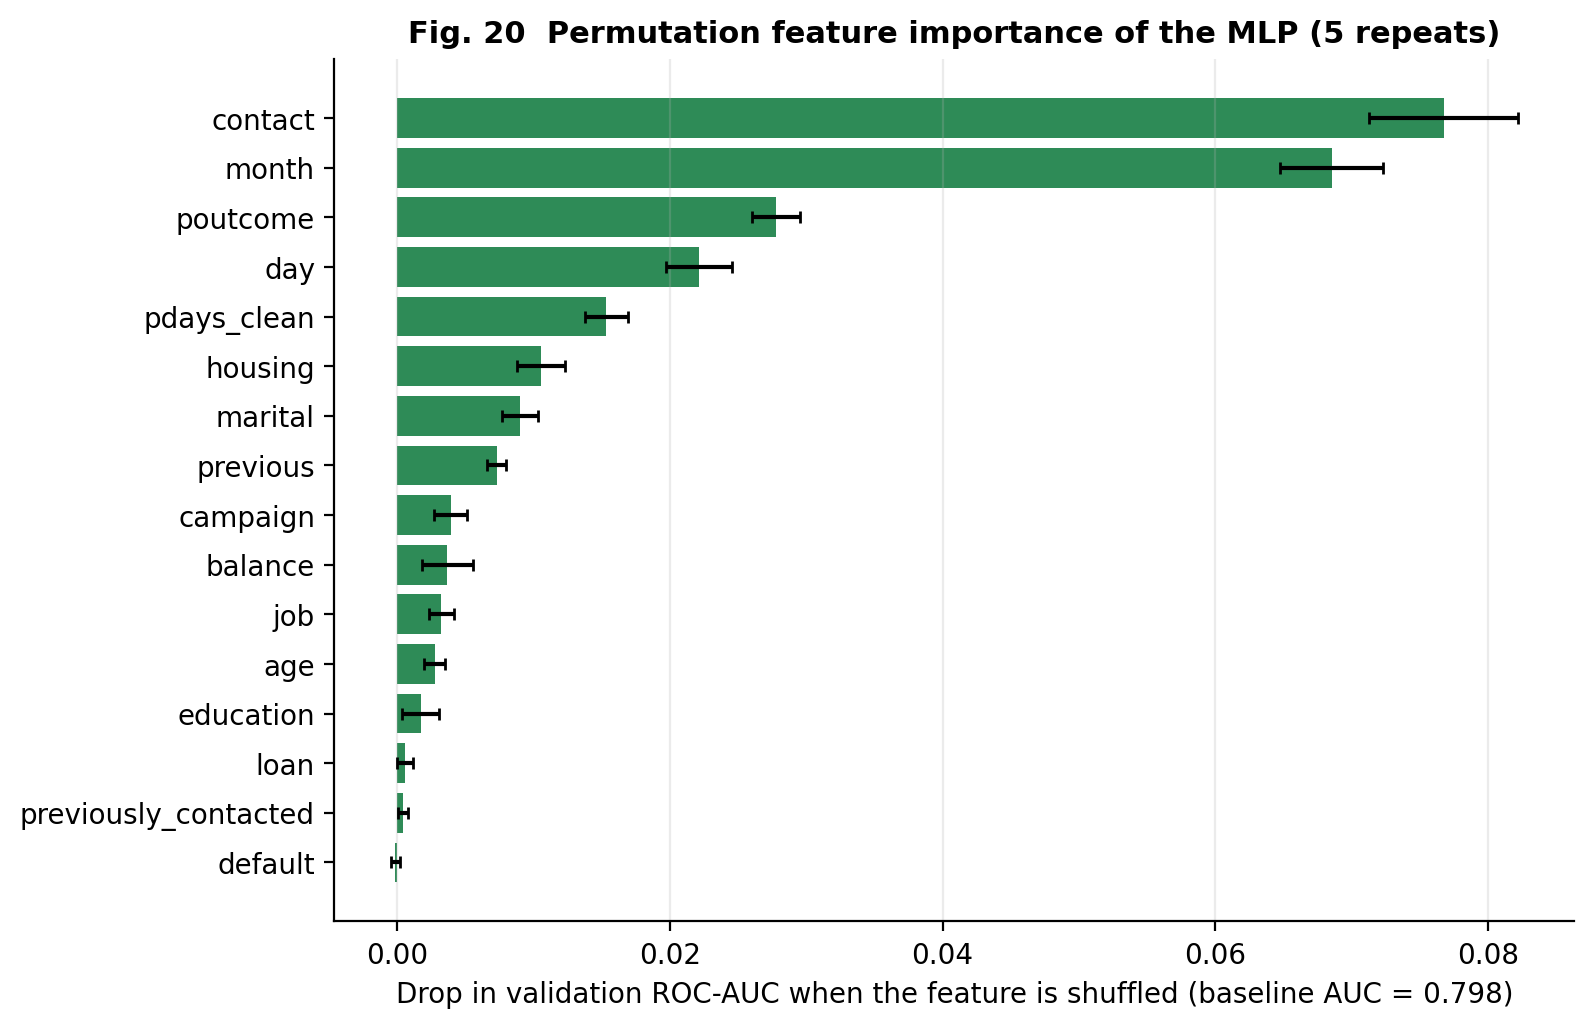

In [32]:
display(Image(str(FIG_DIR / 'fig20_permutation_importance.png'), width=850))

**Figure 20 - Permutation feature importance**

| | |
|---|---|
| **Question** | Which input variables does the trained network actually rely on? |
| **What it shows** | Drop in validation ROC-AUC when each original input column is randomly shuffled (one-hot groups shuffled together, 5 repeats). |
| **Why this chart** | Permutation importance is model-agnostic and respects grouped one-hot features; it is computed on validation data to keep the test set pristine. |
| **Variables** | The 16 pre-call input columns. |
| **Finding** | Top features: contact (-0.077 AUC), month (-0.069), poutcome (-0.028); least important: default (-0.0001). |
| **Interpretation** | The ranking largely agrees with the statistical EDA: contact channel, month and previous outcome (poutcome) were among the strongest associations in Figs. 5, 6 and 11. Two points are less expected: day of month ranks fourth although its marginal correlation with the outcome is tiny (rho = -0.03), so the network probably uses it in interaction with month; and housing, the fourth-ranked categorical association with y in Fig. 11, is only mid-table because it overlaps with month and contact. |
| **Caveats** | Importance is not causation, and correlated features (month, contact, housing, day) share credit, so individual scores understate joint importance. contact and month together largely encode when in the campaign the call happened. |

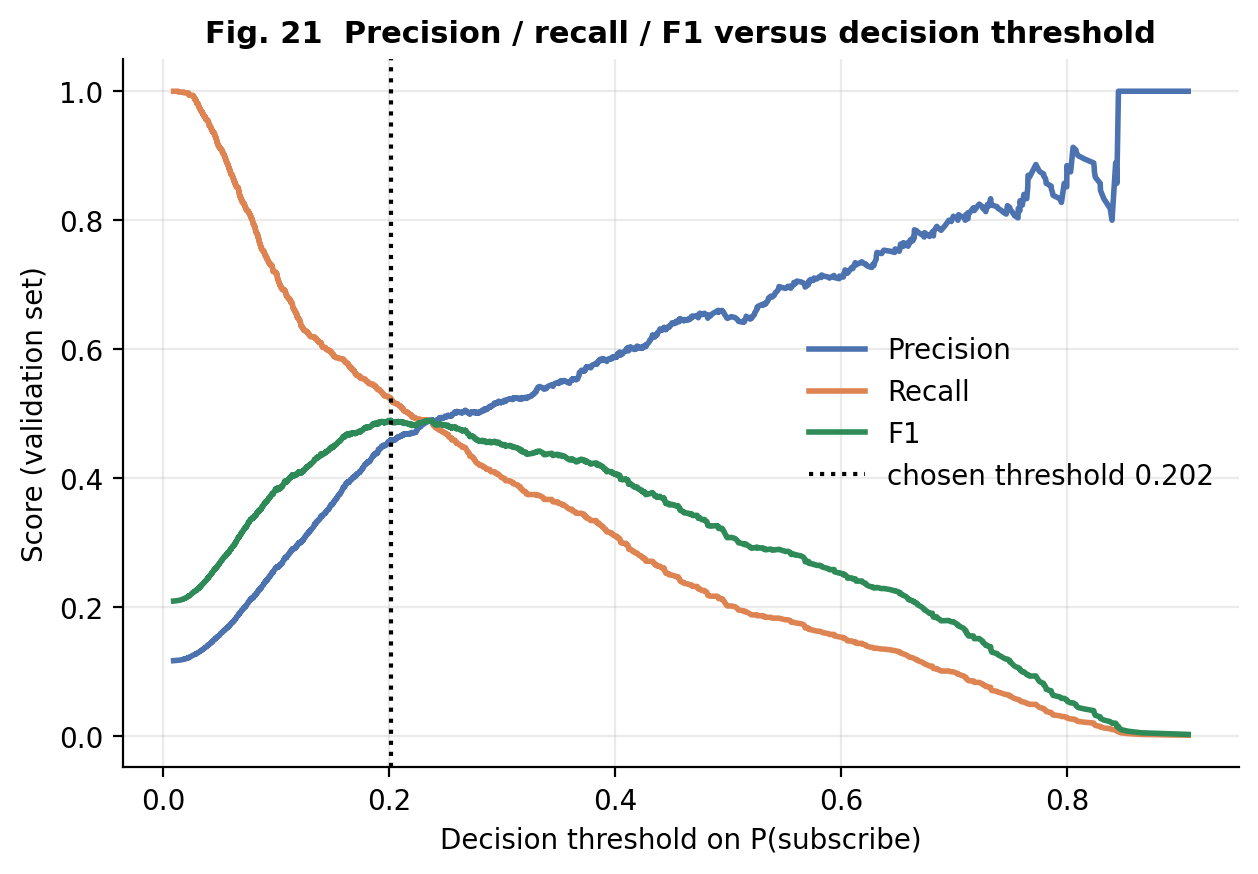

In [33]:
display(Image(str(FIG_DIR / 'fig21_threshold_tradeoff.png'), width=850))

**Figure 21 - Threshold trade-off (validation set)**

| | |
|---|---|
| **Question** | How does the decision threshold trade precision against recall? |
| **What it shows** | Precision, recall and F1 as functions of the cut-off on predicted probability, with the chosen threshold. |
| **Why this chart** | The threshold is a business decision; showing the full trade-off makes the chosen operating point transparent. |
| **Variables** | Threshold, precision, recall, F1 (validation). |
| **Finding** | F1 is maximised at threshold 0.202; the same threshold is applied unchanged to the test set (test F1 0.457). |
| **Interpretation** | Raising the threshold buys precision at the cost of recall; a bank with expensive calls would pick a higher cut-off, and one with cheap calls a lower one. |
| **Caveats** | Chosen on validation only; F1 is not cost-sensitive. |

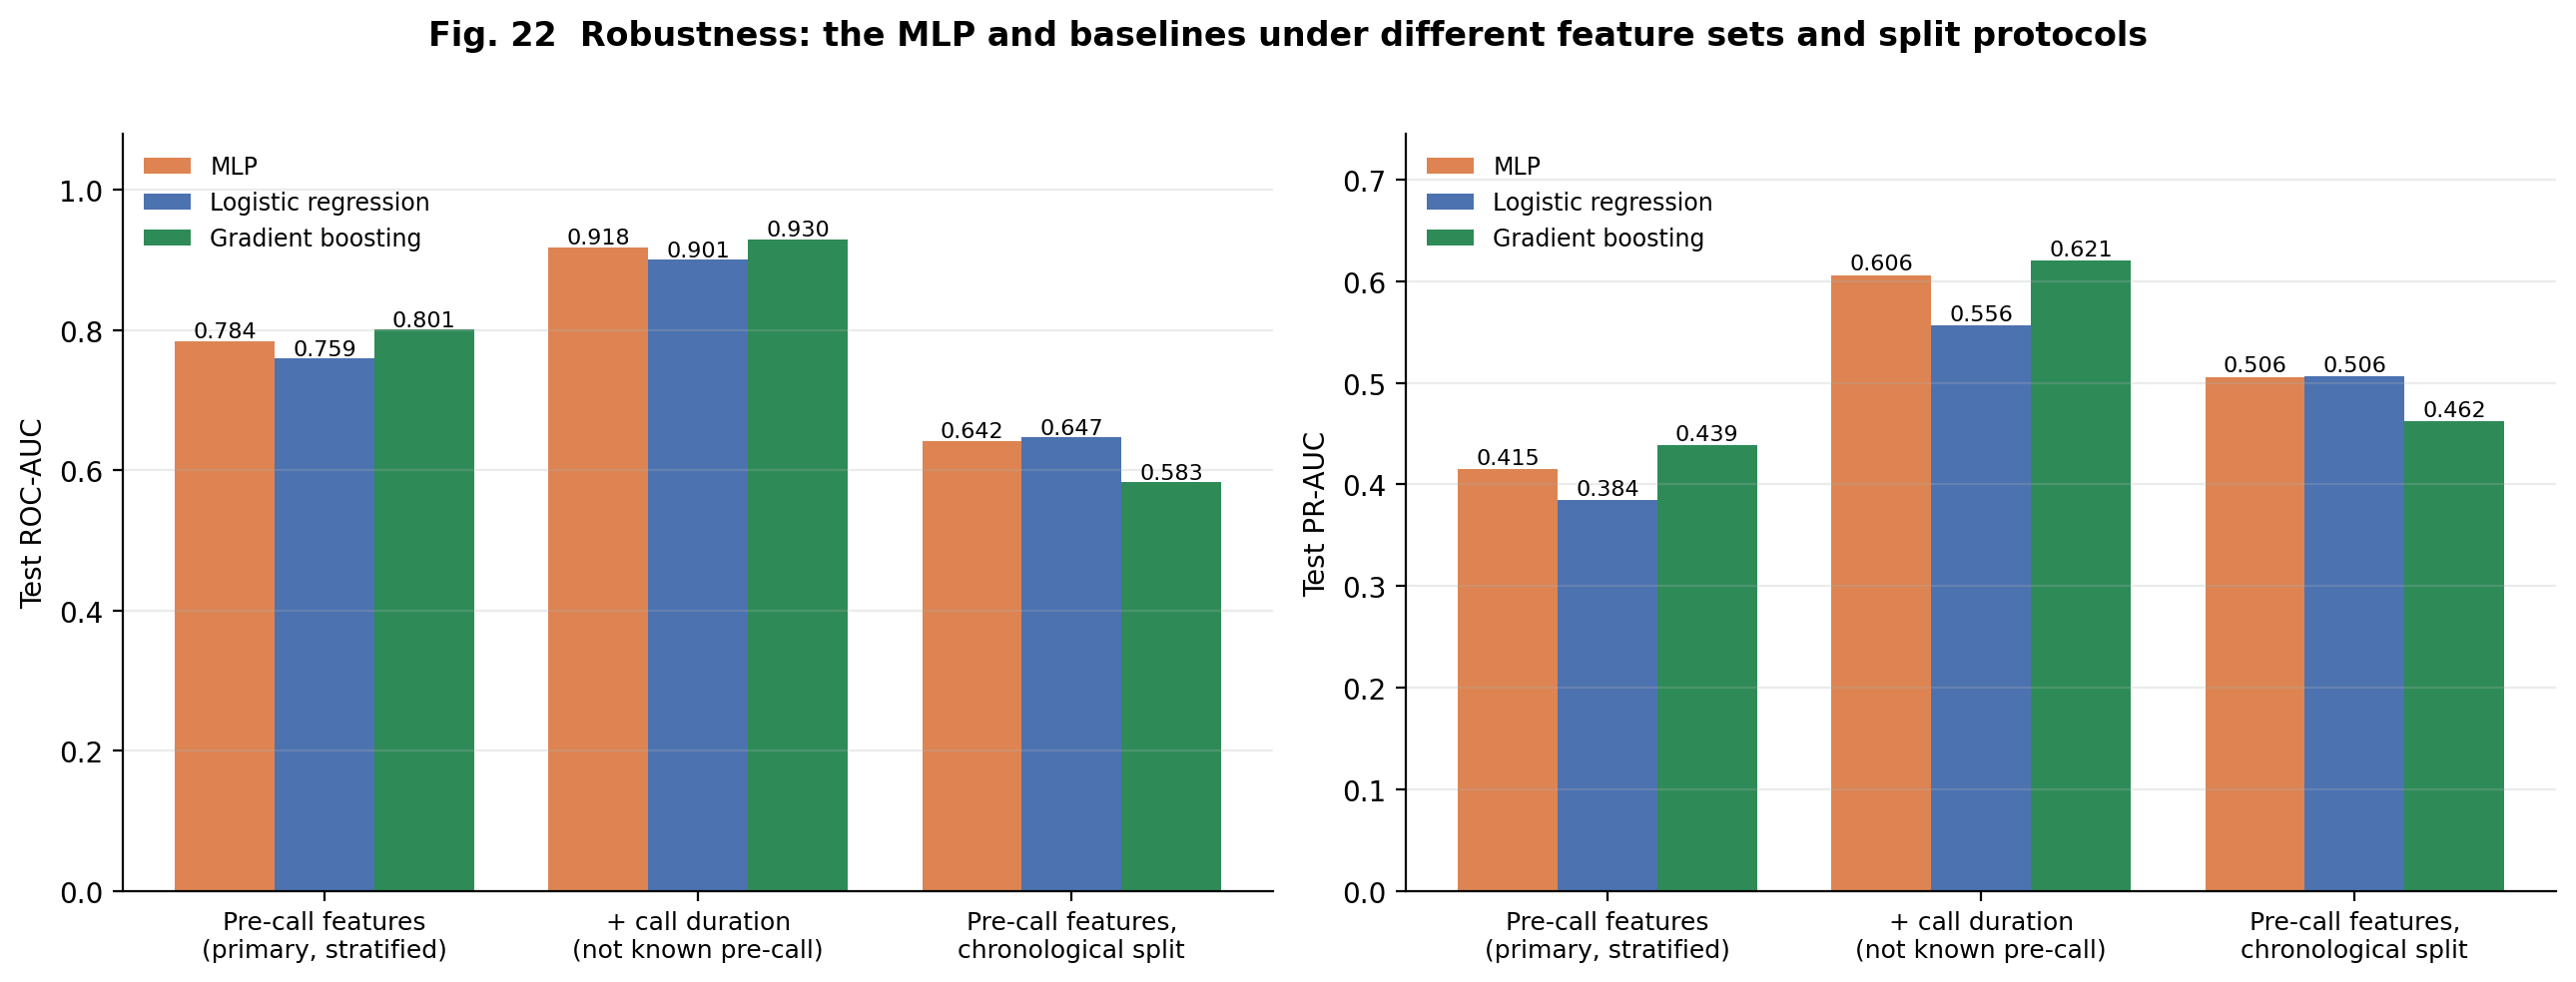

In [34]:
display(Image(str(FIG_DIR / 'fig22_robustness.png'), width=850))

**Figure 22 - Robustness: leakage and temporal shift**

| | |
|---|---|
| **Question** | How trustworthy is the headline result under realistic changes (post-call variable, time-ordered split)? |
| **What it shows** | Test ROC-AUC and PR-AUC of the MLP, logistic regression and gradient boosting under three protocols. |
| **Why this chart** | A single random split can be optimistic; contrasting protocols shows what the score really means. |
| **Variables** | Feature set (with/without duration), split type (stratified/chronological). |
| **Finding** | Adding call duration raises the MLP's test ROC-AUC from 0.784 to 0.918. On a chronological split the pre-call MLP scores ROC-AUC 0.642 (logistic regression 0.647, gradient boosting 0.583); subscription prevalence shifts from 5.8% (train) to 39.3% (test). |
| **Interpretation** | Duration is a strong but unusable signal (it is known only after the call), so the primary model correctly excludes it; the large jump shows how an unnoticed leak would inflate performance. Under the time-ordered split all three models fall to a ROC-AUC of about 0.58-0.65, and the ranking of models changes (gradient boosting, best on the random split, is worst), so the random-split score is an optimistic description of how the model would perform on a later campaign with a different client mix. |
| **Caveats** | The duration and chronological runs use a single seed (42) with the selected configuration; PR-AUC is not comparable across splits with different prevalence. |

## 9. Conclusion and future scope
**What was learned**
- The dataset is a clean-looking but information-hiding table: no NaN cells, yet hidden missingness in poutcome, contact and education and a -1 sentinel in pdays.
- Outcomes are imbalanced (11.7% positive) and driven mainly by the calling month, the previous-campaign outcome, the contact channel and loan status; individual numeric variables are only weakly related to the outcome.

**Model**
- A 32-unit one-hidden-layer MLP (1,697 parameters) reached test ROC-AUC 0.784 +/- 0.002, PR-AUC 0.415, F1 0.461 over five seeds (primary seed: ROC-AUC 0.784, F1 0.457, recall 0.48, precision 0.43).
- It outperformed logistic regression (0.759) but not gradient boosting (0.801); there was no overfitting, and the model is limited by the information available before a call.

**Challenges**
- Hidden missing values and a sentinel code; heavy-tailed variables; multicollinearity among the history variables (VIF 1005 before, 5.2 after).
- A documented leakage trap (duration) and a strong temporal shift (subscription rate 5.8% in the first 70% of the file vs 39.3% in the last 15%).
- Sandbox limits: UCI was unreachable, so a verified mirror was used (download code tries UCI first); no GPU, so the network was kept small.

**Future scope**
- Add the richer UCI 'bank-additional' version (20 inputs including macro-economic indicators such as the Euribor rate) and agent/call-direction features.
- Model count variables with Negative-Binomial/hurdle regressions and age non-linearly (splines); try gradient boosting with calibration and cost-sensitive thresholds.
- Evaluate with rolling-origin (time-series) validation, report uncertainty with bootstrapped intervals, and estimate uplift/profit curves instead of F1.
- Before any deployment: fairness review (age and job effects), monitoring for drift, and a pilot A/B test; a high AUC alone does not justify deployment.